# TT2 · Detección y Mitigación de Calibration Drift — Airline Delay
**Trabajo Terminal 2026-B080 · ESCOM-IPN** · Casas Aguilar José David · Robles Cervantes Pedro Iván

Notebook final de código (fase TT2) para el dataset *Airline Delay* (`Airline.arff`, OpenML 1169). Se ejecuta de punta a punta en Google Colab y deja exportados el modelo, el pipeline de preprocesamiento, el historial de retrasos y las tablas que consumirá el dashboard.

**Qué corrige respecto de TT1**

| Problema detectado en TT1 | Corrección en TT2 | Sección |
|---|---|---|
| Se trató el orden de filas como tiempo continuo; en realidad son 31 días, cada uno ordenado por hora de salida | Reconstrucción del índice de día y partición alineada a días completos | 1.5–1.6, 2.1 |
| Ventanas de 500 vuelos consecutivos (≈ 1 h de un solo día) → PSI ≈ 8 y 100 % de alertas por puro reloj | Diagnóstico explícito; la unidad de decisión es el día y el PSI excluye el calendario | 1.6, 4.6 |
| `Flight` usado como número y códigos de aeropuerto escalados como si tuvieran orden | `Flight` solo como llave de historial; categóricas nativas (XGBoost) y one-hot con agrupación de raras (LR) | 2.2, 2.4 |
| `LabelEncoder` ajustado con todo el dataset (fuga de vocabulario) | Vocabularios congelados con train; categorías no vistas → desconocido | 2.2 |
| Sin ingeniería de variables | Historial causal de retrasos por vuelo, ruta, aeropuertos y aerolínea (solo días anteriores) | 2.3 |
| Recalibración evaluada *in-sample* y ~807 intervenciones | Evaluación prequential diaria con etiquetas del día anterior; el enfoque TT1 queda como "oráculo" | 4.6 |
| Umbrales PSI fijos | Umbrales empíricos (distribución nula) para PSI y para la prueba de calibración | 2.6, 4.6 |
| Latencia y falsas alarmas "N/A" | Validación del monitor con escenarios de verdad conocida | 4.7 |
| Sin tiempos de procesamiento | Registro por etapa, repeticiones y hardware | 1.2, 3.5, 5.5 |

**Observaciones del jurado → dónde se atienden**
1. Tiempos de procesamiento → registro `TIMINGS` en todo el notebook, `%%time` en entrenamiento, §3.5 y §5.5
2. Justificación de modelos → §3.1 y evidencia empírica §3.6–3.7
3. Explicación de los datos sin tecnicismos → ficha en lenguaje llano §1.5
4. Requisitos de un dataset candidato → validador `validate_dataset()` §1.7
5. Maquetado del dashboard → contrato de artefactos y mapeo a vistas §5.4
6. Análisis estático vs ajuste de dimensionalidad → §2.5

## 1. Configuración y carga
### 1.1 Instalación de dependencias
Colab ya incluye pandas, NumPy, SciPy (con `scipy.io.arff`) y matplotlib; aquí se aseguran versiones mínimas de las librerías críticas. XGBoost ≥ 2.0 es necesario por el soporte nativo de variables categóricas.

In [1]:
%pip install -q "xgboost>=2.0" "scikit-learn>=1.3" "pyarrow>=14" psutil joblib

### 1.2 Importaciones, configuración central, registro de tiempos y entorno
- Toda decisión paramétrica vive en `CONFIG` (trazabilidad).
- `timed()` registra duración y memoria de cada etapa en `TIMINGS`; la tabla se exporta para el dashboard (**observación 1**).
- `ENV` documenta el hardware y las versiones: los tiempos solo son comparables con el mismo entorno.

In [2]:
import os, sys, io, re, json, time, hashlib, platform, shutil, importlib, warnings
import datetime as dt
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil, joblib, scipy, sklearn
import xgboost as xgb
from scipy import stats
from scipy.io import arff
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, confusion_matrix, roc_curve,
                             f1_score, precision_score, recall_score, balanced_accuracy_score)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

IN_COLAB = "google.colab" in sys.modules
NOTEBOOK_T0 = time.perf_counter()
SEED = 42
np.random.seed(SEED)
RUN_ID = "tt2_airline_" + dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")

CONFIG = {
    "seed": SEED,
    "data_dir": os.environ.get("AIRLINE_DATA_DIR", "/content/airline_data" if IN_COLAB else "./data/airline"),
    "artifacts_dir": f"./artifacts/airline/{RUN_ID}",
    "train_days": 18, "cal_days": 3,                      # días 0–17 train · 18–20 calibración · 21–30 producción
    "inner_val_days": 3,                                   # últimos días de train: validación temporal interna
    "n_jobs": os.cpu_count() or 1,
    "xgb_params": dict(max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=20,
                       reg_lambda=1.0, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1),
    "xgb_max_rounds": 2000, "xgb_early_stopping": 100,
    "lr_C_grid": [0.01, 0.1, 1.0], "onehot_min_frequency": 200,
    "history_smoothing_m": 20,                             # suavizado bayesiano del historial de retrasos
    "calib_methods": ["none", "temperature", "platt", "isotonic"], "calib_cv_folds": 5,
    "bootstrap_B": 200,
    "psi_bins": 10, "psi_max_categories": 30, "psi_null_B": 200, "psi_null_sizes": [500, 1000, 2000, 17000],
    "recal_buffer_days": 3, "retrain_cooldown_days": 2, "calendar_K_days": 3,
    "risk_cuts": [0.35, 0.60], "threshold_rule": "youden",
    "timing_repeats": 3, "run_extended_benchmark": True, "benchmark_rows": 100_000,
    "monitor_block": 500, "monitor_validation_R": 20, "label_shift_pp": [0.05, 0.10, 0.15],
    "tt1_window": 500, "tt1_stride": 200,
    "download_artifacts": False,
}
XGB_PARAMS = {**CONFIG["xgb_params"], "random_state": SEED, "n_jobs": CONFIG["n_jobs"]}
Path("src").mkdir(exist_ok=True)
ART = Path(CONFIG["artifacts_dir"])
ART.mkdir(parents=True, exist_ok=True)

TIMINGS = []

@contextmanager
def timed(stage, **meta):
    """Registra duración (s) y memoria RSS (MB) de una etapa en TIMINGS."""
    t0 = time.perf_counter()
    try:
        yield
    finally:
        secs = time.perf_counter() - t0
        rss = psutil.Process().memory_info().rss / 1e6
        TIMINGS.append({"etapa": stage, "segundos": secs, "rss_mb": rss, **meta})
        print(f"⏱  {stage}: {secs:,.3f} s  (RSS {rss:,.0f} MB)")

def save_table(df, name):
    """Guarda una tabla para el dashboard (parquet si hay pyarrow; si no, CSV)."""
    try:
        path = ART / f"{name}.parquet"
        df.to_parquet(path, index=False)
    except Exception:
        path = ART / f"{name}.csv"
        df.to_csv(path, index=False)
    return path

ENV = {"python": platform.python_version(), "sistema": platform.platform(),
       "procesador": platform.processor() or platform.machine(), "cpus_logicos": os.cpu_count(),
       "ram_gb": round(psutil.virtual_memory().total / 1e9, 1), "colab": IN_COLAB,
       "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
       "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "run_id": RUN_ID}
pd.Series(ENV, name="entorno").to_frame()

,entorno
python,3.13.16
sistema,Linux-6.6.122+-x86_64-with-glibc2.39
procesador,x86_64
cpus_logicos,2
ram_gb,13.6
colab,True
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1


### 1.3 Módulo reutilizable `airline_tt2.py` (notebook ↔ dashboard)
Las piezas que el dashboard necesitará se escriben en un archivo `.py`:
- El **historial causal** de retrasos (`causal_lags` y `HistoryStore`).
- El esquema de variables (`AirlineFeaturizer`).
- Los calibradores, el PSI y las métricas.
- El objeto `DelayScorer`.

Así `joblib` serializa las clases por referencia a `airline_tt2` y el dashboard las carga con `import airline_tt2`.

In [3]:
%%writefile src/airline_tt2.py
"""airline_tt2 — componentes reutilizables del TT2 (2026-B080) para Airline Delay.

Lo importan el notebook y el futuro dashboard: llaves e historial causal de retrasos,
construcción de variables, pipeline lineal, calibradores, PSI (numérico y categórico),
métricas y el objeto DelayScorer. Al vivir en un módulo, joblib serializa estas clases por
referencia a `airline_tt2` y el dashboard las carga con `import airline_tt2`.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.compose import ColumnTransformer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RAW_COLUMNS = ["Airline", "Flight", "AirportFrom", "AirportTo", "DayOfWeek", "Time", "Length"]
CAT_FEATURES = ["Airline", "AirportFrom", "AirportTo"]
LAG_KEYS = {"fl": "vuelo (aerolínea + número)", "route": "ruta (origen → destino)", "orig": "aeropuerto de origen",
            "dest": "aeropuerto de destino", "airline": "aerolínea"}
RATE_FEATURES = [f"h_{k}" for k in LAG_KEYS] + [f"p_{k}" for k in LAG_KEYS] + ["prev_day_rate"]
COUNT_FEATURES = ["n_fl", "n_route"]
LAG_FEATURES = RATE_FEATURES + COUNT_FEATURES
BASE_NUMERIC = ["Time", "Length", "sin_t", "cos_t"]
XGB_FEATURES = CAT_FEATURES + ["DayOfWeek"] + BASE_NUMERIC + LAG_FEATURES
MONITOR_FEATURES = ["Airline", "AirportFrom", "AirportTo", "Time", "Length"]
RISK_LABELS = ("Bajo", "Medio", "Alto")
EPS = 1e-6

FEATURE_LABELS = {
    "Airline": "Aerolínea", "Flight": "Número de vuelo (identificador)", "AirportFrom": "Aeropuerto de origen",
    "AirportTo": "Aeropuerto de destino", "DayOfWeek": "Día de la semana", "Time": "Hora de salida (min desde 00:00)",
    "Length": "Duración programada (min)", "sin_t": "Hora de salida (componente seno)", "cos_t": "Hora de salida (componente coseno)",
    "prev_day_rate": "Tasa global de retraso del día anterior",
    "n_fl": "Historial del vuelo (n.º de operaciones previas, log)", "n_route": "Historial de la ruta (n.º de vuelos previos, log)",
    **{f"h_{k}": f"Tasa histórica de retraso · {v}" for k, v in LAG_KEYS.items()},
    **{f"p_{k}": f"Tasa de retraso del día anterior · {v}" for k, v in LAG_KEYS.items()},
}


# ----------------------------------------------------------------------------- historial causal
def make_keys(df: pd.DataFrame) -> pd.DataFrame:
    """Llaves de historial: vuelo, ruta, origen, destino y aerolínea (como texto)."""
    flight = pd.to_numeric(df["Flight"], errors="coerce").astype("Int64").astype(str)
    return pd.DataFrame({"fl": df["Airline"].astype(str) + "_" + flight,
                         "route": df["AirportFrom"].astype(str) + "-" + df["AirportTo"].astype(str),
                         "orig": df["AirportFrom"].astype(str), "dest": df["AirportTo"].astype(str),
                         "airline": df["Airline"].astype(str)}, index=df.index)


def causal_lags(df: pd.DataFrame, prior: float, m: float = 20.0) -> pd.DataFrame:
    """Variables de historial para CADA fila usando solo etiquetas de días anteriores (sin fuga).

    h_k: tasa histórica suavizada hasta el día d−1 · p_k: tasa del día d−1 · n_k: log(1 + n.º de vuelos previos).
    Suavizado bayesiano: (retrasos + m·prior) / (vuelos + m).
    """
    keys, day, y = make_keys(df), df["day"].to_numpy(), df["Delay"].to_numpy(dtype=float)
    out = pd.DataFrame(index=df.index)
    for k in LAG_KEYS:
        g = (pd.DataFrame({"key": keys[k].to_numpy(), "day": day, "y": y})
             .groupby(["key", "day"], sort=True)["y"].agg(["sum", "count"]).reset_index())
        gk = g.groupby("key")
        g["cs"], g["cc"] = gk["sum"].cumsum() - g["sum"], gk["count"].cumsum() - g["count"]
        ok = gk["day"].shift(1) == g["day"] - 1
        ps, pc = gk["sum"].shift(1), gk["count"].shift(1)
        g["h"] = (g["cs"] + m * prior) / (g["cc"] + m)
        g["p"] = np.where(ok, (ps + m * prior) / (pc + m), prior)
        g["n"] = np.log1p(g["cc"])
        mg = pd.DataFrame({"key": keys[k].to_numpy(), "day": day}).merge(g[["key", "day", "h", "p", "n"]], on=["key", "day"], how="left")
        out[f"h_{k}"], out[f"p_{k}"] = mg["h"].to_numpy(), mg["p"].to_numpy()
        if f"n_{k}" in COUNT_FEATURES:
            out[f"n_{k}"] = mg["n"].to_numpy()
    rate = pd.Series(y).groupby(day).mean()
    out["prev_day_rate"] = pd.Series(day - 1).map(rate).fillna(prior).to_numpy()
    return out[LAG_FEATURES]


class HistoryStore:
    """Estado del historial para inferencia en línea: acumulados por llave hasta el último día etiquetado."""

    def __init__(self, prior, m=20.0):
        self.prior, self.m = float(prior), float(m)

    def fit(self, df):
        keys, y = make_keys(df), df["Delay"].astype(float)
        self.last_day_ = int(df["day"].max())
        last = (df["day"] == self.last_day_).to_numpy()
        self.cum_ = {k: y.groupby(keys[k]).agg(["sum", "count"]) for k in LAG_KEYS}
        self.last_ = {k: y[last].groupby(keys[k][last]).agg(["sum", "count"]) for k in LAG_KEYS}
        self.last_rate_ = float(y[last].mean())
        return self

    def update(self, df_new):
        """Agrega uno o más días nuevos ya etiquetados (el dashboard lo llamaría al cierre de cada día)."""
        keys, y = make_keys(df_new), df_new["Delay"].astype(float)
        new_last = int(df_new["day"].max())
        last = (df_new["day"] == new_last).to_numpy()
        for k in LAG_KEYS:
            self.cum_[k] = self.cum_[k].add(y.groupby(keys[k]).agg(["sum", "count"]), fill_value=0)
            self.last_[k] = y[last].groupby(keys[k][last]).agg(["sum", "count"])
        self.last_day_, self.last_rate_ = new_last, float(y[last].mean())
        return self

    def lookup(self, df):
        """Variables de historial para vuelos del día siguiente al último día etiquetado."""
        keys, m, pr = make_keys(df), self.m, self.prior
        out = pd.DataFrame(index=df.index)
        for k in LAG_KEYS:
            c = self.cum_[k].reindex(keys[k].to_numpy())
            l = self.last_[k].reindex(keys[k].to_numpy())
            cs, cc = c["sum"].fillna(0).to_numpy(), c["count"].fillna(0).to_numpy()
            out[f"h_{k}"] = (cs + m * pr) / (cc + m)
            ls, lc = l["sum"].to_numpy(dtype=float), l["count"].to_numpy(dtype=float)
            out[f"p_{k}"] = np.where(np.isnan(lc), pr, (np.nan_to_num(ls) + m * pr) / (np.nan_to_num(lc) + m))
            if f"n_{k}" in COUNT_FEATURES:
                out[f"n_{k}"] = np.log1p(cc)
        out["prev_day_rate"] = self.last_rate_
        return out[LAG_FEATURES]


# ----------------------------------------------------------------------------- variables
class AirlineFeaturizer:
    """Esquema estático: vocabularios categóricos congelados en train (no vistos → NaN) + hora cíclica + historial."""

    def fit(self, df):
        self.categories_ = {c: sorted(df[c].astype(str).unique().tolist()) for c in CAT_FEATURES}
        return self

    def transform(self, df, lags):
        X = pd.DataFrame(index=df.index)
        for c in CAT_FEATURES:
            v = df[c].astype(str)
            X[c] = pd.Categorical(v.where(v.isin(self.categories_[c])), categories=self.categories_[c])
        for c in ["DayOfWeek", "Time", "Length"]:
            X[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
        X["sin_t"] = np.sin(2 * np.pi * X["Time"] / 1440)
        X["cos_t"] = np.cos(2 * np.pi * X["Time"] / 1440)
        X = pd.concat([X, pd.DataFrame(np.asarray(lags[LAG_FEATURES], dtype=float), columns=LAG_FEATURES, index=df.index)], axis=1)
        return X[XGB_FEATURES]


def monitor_frame(df):
    """Variables crudas que vigila el PSI (el día de la semana se excluye: es calendario, no drift)."""
    X = pd.DataFrame({c: df[c].astype(str) for c in ["Airline", "AirportFrom", "AirportTo"]}, index=df.index)
    for c in ["Time", "Length"]:
        X[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
    return X[MONITOR_FEATURES]


def _logit(Z):
    Z = np.clip(np.asarray(Z, dtype=float), 1e-4, 1 - 1e-4)
    return np.log(Z / (1 - Z))


def make_lr_pipeline(C=0.1, class_weight=None, min_frequency=200, lags=True):
    """One-hot (categorías raras agrupadas) + hora cíclica + logit de tasas históricas → LR."""
    cat = CAT_FEATURES + ["DayOfWeek"]
    tr = [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency), cat),
          ("num", StandardScaler(), ["Length", "sin_t", "cos_t"])]
    if lags:
        tr += [("rates", Pipeline([("logit", FunctionTransformer(_logit, feature_names_out="one-to-one")),
                                   ("sc", StandardScaler())]), RATE_FEATURES),
               ("counts", StandardScaler(), COUNT_FEATURES)]
    return Pipeline([("prep", ColumnTransformer(tr, verbose_feature_names_out=False)),
                     ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=3000))])


# ----------------------------------------------------------------------------- calibradores
def _clip(p):
    return np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)


def logit(p):
    p = _clip(p)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


class IdentityCalibrator:
    name = "none"

    def fit(self, p, y):
        return self

    def predict(self, p):
        return _clip(p)


class TemperatureScaler:
    """p' = σ(logit(p)/T). Un parámetro; corrige sobre/subconfianza pero no un sesgo de prevalencia."""
    name = "temperature"

    def fit(self, p, y):
        z, y = logit(p), np.asarray(y, dtype=float)

        def nll(T):
            q = _clip(sigmoid(z / T))
            return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

        self.T_ = float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)
        return self

    def predict(self, p):
        return _clip(sigmoid(logit(p) / self.T_))


class PlattScaler:
    """p' = σ(a·logit(p) + b). Escala (a) y sesgo (b): corrige también cambios de prevalencia."""
    name = "platt"

    def fit(self, p, y):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), np.asarray(y).astype(int))
        self.a_, self.b_ = float(lr.coef_[0, 0]), float(lr.intercept_[0])
        return self

    def predict(self, p):
        return _clip(sigmoid(self.a_ * logit(p) + self.b_))


class IsotonicCalibrator:
    """Función monótona no paramétrica; flexible, requiere muchos datos."""
    name = "isotonic"

    def fit(self, p, y):
        self.iso_ = IsotonicRegression(y_min=EPS, y_max=1 - EPS, out_of_bounds="clip")
        self.iso_.fit(np.asarray(p, dtype=float), np.asarray(y, dtype=float))
        return self

    def predict(self, p):
        return _clip(self.iso_.predict(np.asarray(p, dtype=float)))


CALIBRATORS = {"none": IdentityCalibrator, "temperature": TemperatureScaler, "platt": PlattScaler, "isotonic": IsotonicCalibrator}


def make_calibrator(name):
    return CALIBRATORS[name]()


# ----------------------------------------------------------------------------- PSI
class PSIReference:
    """PSI por variable. Numéricas: deciles de la referencia + bin NaN. Categóricas: top-K categorías + 'otras' + NaN."""

    def __init__(self, n_bins=10, max_categories=30, eps=1e-4):
        self.n_bins, self.max_categories, self.eps = n_bins, max_categories, eps

    @staticmethod
    def _is_num(s):
        return pd.api.types.is_numeric_dtype(s) and not isinstance(s.dtype, pd.CategoricalDtype)

    def fit(self, X: pd.DataFrame):
        self.features_, self.edges_, self.cats_, self.ref_ = list(X.columns), {}, {}, {}
        for c in self.features_:
            s = X[c]
            if self._is_num(s):
                v = s.to_numpy(dtype=float)
                fin = v[~np.isnan(v)]
                inner = np.unique(np.quantile(fin, np.linspace(0, 1, self.n_bins + 1))[1:-1]) if fin.size else np.array([])
                self.edges_[c], self.cats_[c] = np.concatenate([[-np.inf], inner, [np.inf]]), None
            else:
                vc = s.astype(object).dropna().value_counts()
                self.cats_[c], self.edges_[c] = list(vc.index[: self.max_categories]), None
            self.ref_[c] = self._props(s, c)
        return self

    def _props(self, s, c):
        if self.cats_[c] is None:
            v = s.to_numpy(dtype=float)
            nan = np.isnan(v)
            counts = np.append(np.histogram(v[~nan], bins=self.edges_[c])[0], nan.sum()).astype(float)
        else:
            v = s.astype(object)
            nan = v.isna().to_numpy()
            code = v.map({cat: i for i, cat in enumerate(self.cats_[c])}).to_numpy(dtype=float)
            known = ~np.isnan(code)
            counts = np.bincount(code[known].astype(int), minlength=len(self.cats_[c])).astype(float)
            counts = np.append(counts, [(~known & ~nan).sum(), nan.sum()])
        return counts / max(len(s), 1)

    def transform(self, X: pd.DataFrame) -> pd.Series:
        out = {}
        for c in self.features_:
            q, p = self._props(X[c], c) + self.eps, self.ref_[c] + self.eps
            out[c] = float(np.sum((q - p) * np.log(q / p)))
        return pd.Series(out)


def psi_null_thresholds(ref_df, psi_ref, n, B=200, seed=42, qs=(0.95, 0.99)):
    """Distribución nula de PSI_máx para muestras de tamaño n sin drift (bootstrap)."""
    rng, m = np.random.default_rng(seed), len(ref_df)
    vals = np.array([psi_ref.transform(ref_df.iloc[rng.integers(0, m, n)]).max() for _ in range(B)])
    return {"media": float(vals.mean()), "p95": float(np.quantile(vals, qs[0])), "p99": float(np.quantile(vals, qs[1]))}


def fit_psi_monitor(ref_df, sizes, B=200, seed=42, n_bins=10, max_categories=30):
    """Referencia con una mitad aleatoria de ref_df; distribución nula muestreada de la otra mitad (independiente)."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(ref_df))
    half = len(idx) // 2
    ref = PSIReference(n_bins=n_bins, max_categories=max_categories).fit(ref_df.iloc[idx[:half]])
    null_src = ref_df.iloc[idx[half:]]
    return ref, {int(n): psi_null_thresholds(null_src, ref, n=int(n), B=B, seed=seed) for n in sizes}


def calibration_z(y, p):
    """z = (observados − esperados) / sqrt(Σ p(1−p)): calibración en lo grande."""
    p = np.asarray(p, dtype=float)
    var = float(np.sum(p * (1 - p)))
    return (float(np.sum(y)) - float(p.sum())) / np.sqrt(var) if var > 0 else float("nan")


def z_null_thresholds(y, p, n, B=500, seed=42, qs=(0.95, 0.99)):
    """Percentiles de |z| en muestras de tamaño n sin drift, con predicciones fuera de muestra."""
    rng, y, p = np.random.default_rng(seed), np.asarray(y), np.asarray(p, dtype=float)
    zs = np.abs([calibration_z(y[i], p[i]) for i in (rng.integers(0, len(y), n) for _ in range(B))])
    return {"media": float(np.nanmean(zs)), "p95": float(np.nanquantile(zs, qs[0])), "p99": float(np.nanquantile(zs, qs[1]))}


# ----------------------------------------------------------------------------- métricas
def ece_uniform(y, p, n_bins=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(np.abs(np.bincount(b, y, n_bins) - np.bincount(b, p, n_bins)).sum() / len(y))


def ace_equal_mass(y, p, n_bins=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    chunks = np.array_split(np.argsort(p, kind="mergesort"), n_bins)
    return float(sum(len(c) * abs(y[c].mean() - p[c].mean()) for c in chunks if len(c)) / len(y))


def mce_uniform(y, p, n_bins=10, min_count=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    cnt, sp, sy = np.bincount(b, minlength=n_bins), np.bincount(b, p, n_bins), np.bincount(b, y, n_bins)
    m = cnt >= min_count
    return float(np.max(np.abs(sy[m] - sp[m]) / cnt[m])) if m.any() else float("nan")


def calibration_intercept_slope(y, p):
    """Calibración en lo grande (CITL, ideal 0) y pendiente de calibración (ideal 1)."""
    z, y = logit(p), np.asarray(y, dtype=float)
    slope = float(LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y.astype(int)).coef_[0, 0])

    def nll(a):
        q = _clip(sigmoid(a + z))
        return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

    return float(minimize_scalar(nll, bounds=(-10, 10), method="bounded").x), slope


def ks_separation(y, p):
    """KS entre las distribuciones de score de vuelos retrasados y puntuales."""
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    r = stats.ks_2samp(p[y == 1], p[y == 0])
    return float(r.statistic), float(r.pvalue)


def evaluate_probs(y, p, prior=None):
    y, p = np.asarray(y).astype(int), _clip(p)
    both = len(np.unique(y)) == 2
    brier = brier_score_loss(y, p)
    prior = y.mean() if prior is None else prior
    brier_ref = np.mean((prior - y) ** 2)
    out = {"n": len(y), "positivos": int(y.sum()), "prevalencia": float(y.mean()), "p_media": float(p.mean()),
           "AUC": roc_auc_score(y, p) if both else np.nan, "AP": average_precision_score(y, p) if both else np.nan,
           "Brier": brier, "BSS": 1 - brier / brier_ref if brier_ref > 0 else np.nan,
           "LogLoss": log_loss(y, p, labels=[0, 1]), "ECE": ece_uniform(y, p), "ACE": ace_equal_mass(y, p),
           "MCE": mce_uniform(y, p), "O/E": float(y.sum() / p.sum()),
           "CITL": np.nan, "Pendiente": np.nan, "KS": np.nan, "KS_p": np.nan}
    if both:
        out["CITL"], out["Pendiente"] = calibration_intercept_slope(y, p)
        out["KS"], out["KS_p"] = ks_separation(y, p)
    return out


def reliability_table(y, p, n_bins=10, strategy="uniform"):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    if strategy == "quantile":
        g = np.empty(len(p), dtype=int)
        for i, chunk in enumerate(np.array_split(np.argsort(p, kind="mergesort"), n_bins)):
            g[chunk] = i
    else:
        g = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return (pd.DataFrame({"bin": g, "y": y, "p": p}).groupby("bin")
            .agg(n=("y", "size"), p_media=("p", "mean"), frecuencia_observada=("y", "mean")).reset_index())


# ----------------------------------------------------------------------------- scorer para el dashboard
_EXPLAIN_BASES = CAT_FEATURES + ["DayOfWeek"] + BASE_NUMERIC + LAG_FEATURES


def _base_name(name):
    hits = [b for b in _EXPLAIN_BASES if name == b or name.startswith(b + "_")]
    return max(hits, key=len) if hits else name


class DelayScorer:
    """Modelo + calibrador + esquema de variables + umbral + bandas de riesgo + explicación local."""

    def __init__(self, name, kind, model, calibrator, featurizer, threshold, risk_cuts=(0.35, 0.60)):
        self.name, self.kind, self.model, self.calibrator, self.featurizer = name, kind, model, calibrator, featurizer
        self.threshold, self.risk_cuts = float(threshold), tuple(risk_cuts)

    def features(self, df, history):
        return self.featurizer.transform(df, history.lookup(df))

    def raw_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

    def predict_proba(self, X):
        return self.calibrator.predict(self.raw_proba(X))

    def risk_band(self, p):
        return pd.cut(np.asarray(p), bins=[0.0, *self.risk_cuts, 1.0 + 1e-9], labels=list(RISK_LABELS),
                      right=False, include_lowest=True).astype(str)

    def explain(self, X):
        """Contribuciones en log-momios (SHAP nativo en XGBoost; coef×valor en LR, agregadas por variable)."""
        if self.kind == "xgb":
            import xgboost as xgb
            contrib = self.model.get_booster().predict(xgb.DMatrix(X, enable_categorical=True), pred_contribs=True)[:, :-1]
            return pd.DataFrame(contrib, columns=list(X.columns), index=X.index)
        prep = self.model[:-1]
        Z = prep.transform(X)
        Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
        names = [_base_name(n) for n in prep.get_feature_names_out()]
        C = pd.DataFrame(Z * self.model[-1].coef_[0], columns=names, index=X.index)
        return C.T.groupby(level=0).sum().T

    def predict(self, df, history, top_k=3, explain=True, labels=None):
        labels = labels or FEATURE_LABELS
        X = self.features(df, history)
        p = self.predict_proba(X)
        out = pd.DataFrame({"prob_retraso": p, "banda_riesgo": self.risk_band(p), "alerta": (p >= self.threshold).astype(int),
                            "historial_vuelo": np.round(np.expm1(X["n_fl"].to_numpy())).astype(int)}, index=df.index)
        if explain:
            C = self.explain(X)
            tops = []
            for _, row in C.iterrows():
                r = row.reindex(row.abs().sort_values(ascending=False).index[:top_k])
                tops.append("; ".join(f"{k} {'↑' if v > 0 else '↓'} ({labels.get(k, k)[:40]})" for k, v in r.items()))
            out["factores_principales"] = tops
        return out


def score_batch(bundle, df, model="best", explain=True, top_k=3, drift_check=True, min_rows_drift=200):
    """Función que consumirá el dashboard: predicciones + reporte de drift + advertencias de esquema."""
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df debe ser un pandas.DataFrame")
    missing = [c for c in RAW_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Faltan columnas obligatorias: {missing}")
    warns = []
    fz = bundle["scorers"][bundle["best"]].featurizer
    for c in CAT_FEATURES:
        unseen = int((~df[c].astype(str).isin(fz.categories_[c])).sum())
        if unseen:
            warns.append(f"{unseen} fila(s) con {c} no visto en entrenamiento → se trata como desconocido")
    name = bundle["best"] if model == "best" else model
    if name not in bundle["scorers"]:
        raise ValueError(f"Modelo '{name}' no disponible; opciones: {list(bundle['scorers'])}")
    preds = bundle["scorers"][name].predict(df, bundle["history"], top_k=top_k, explain=explain, labels=bundle.get("feature_labels"))
    drift = None
    if drift_check and len(df) >= min_rows_drift:
        psi = bundle["psi_reference"].transform(monitor_frame(df))
        sizes = np.array(sorted(bundle["psi_null"]))
        n_key = int(sizes[np.argmin(np.abs(sizes - len(df)))])
        thr = bundle["psi_null"][n_key]
        lvl = 2 if psi.max() >= thr["p99"] else (1 if psi.max() >= thr["p95"] else 0)
        drift = {"n": int(len(df)), "psi_max": float(psi.max()), "nivel": lvl, "umbral_p95": float(thr["p95"]),
                 "umbral_p99": float(thr["p99"]), "n_referencia_umbral": n_key,
                 "psi_por_variable": {k: round(float(v), 4) for k, v in psi.sort_values(ascending=False).items()}}
    elif drift_check:
        warns.append(f"Verificación de drift omitida: se requieren ≥ {min_rows_drift} filas")
    return {"modelo": name, "predicciones": preds, "drift": drift, "advertencias": warns}

Writing src/airline_tt2.py


In [4]:
sys.path.insert(0, str(Path("src").resolve()))
import airline_tt2
importlib.reload(airline_tt2)
from airline_tt2 import (RAW_COLUMNS, CAT_FEATURES, LAG_FEATURES, RATE_FEATURES, XGB_FEATURES, MONITOR_FEATURES,
                         FEATURE_LABELS, causal_lags, HistoryStore, AirlineFeaturizer, monitor_frame, make_lr_pipeline,
                         make_calibrator, PlattScaler, IdentityCalibrator, PSIReference, psi_null_thresholds,
                         fit_psi_monitor, calibration_z, z_null_thresholds, evaluate_probs, ece_uniform,
                         reliability_table, DelayScorer)
print(f"airline_tt2 cargado · {len(XGB_FEATURES)} variables de modelo ({len(LAG_FEATURES)} de historial)")

airline_tt2 cargado · 21 variables de modelo (13 de historial)


### 1.4 Obtención de los datos
Se busca `Airline.arff` en este orden:
1. En `CONFIG["data_dir"]`: por ejemplo, una carpeta de Google Drive montada con `drive.mount`.
2. Descarga desde OpenML (dataset 1169) con `sklearn.datasets.fetch_openml`.
3. Selector de archivos de Colab (carga manual).

Se calcula el SHA-256 del archivo para que cualquier corrida pueda verificarse contra los mismos datos. Si se usa OpenML, el orden de filas se valida en §1.6: la reconstrucción de días debe dar 31 días consecutivos.

In [5]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def ensure_data(data_dir):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    found = sorted(data_dir.rglob("Airline*.arff")) or sorted(data_dir.rglob("airline*.arff"))
    if found:
        return found[0], "archivo local"
    try:
        from sklearn.datasets import fetch_openml
        print("Descargando OpenML 1169…")
        df = fetch_openml(data_id=1169, as_frame=True, parser="auto").frame
        path = data_dir / "Airline_openml.csv"
        df.to_csv(path, index=False)
        return path, "OpenML 1169"
    except Exception as err:
        print(f"  Descarga no disponible ({err})")
    if IN_COLAB:
        from google.colab import files
        print("Selecciona Airline.arff:")
        for name, content in files.upload().items():
            (data_dir / name).write_bytes(content)
        found = sorted(data_dir.rglob("*.arff"))
        if found:
            return found[0], "carga manual"
    raise FileNotFoundError(f"No se encontró Airline.arff en {data_dir}. Colócalo ahí o ajusta CONFIG['data_dir'].")

with timed("obtencion_datos"):
    DATA_FILE, DATA_SOURCE = ensure_data(CONFIG["data_dir"])
    DATA_HASH = sha256(DATA_FILE)
print(f"Fuente: {DATA_SOURCE} · {DATA_FILE.name} · {DATA_FILE.stat().st_size / 1e6:.1f} MB · SHA-256 {DATA_HASH[:16]}…")

Descargando OpenML 1169…
⏱  obtencion_datos: 22.491 s  (RSS 301 MB)
Fuente: OpenML 1169 · Airline_openml.csv · 14.8 MB · SHA-256 e46fc1537a029488…


### 1.5 Ficha del dataset en lenguaje llano + carga (observación 3)

| Pregunta | Respuesta sin tecnicismos |
|---|---|
| ¿Qué es cada fila? | Un vuelo comercial dentro de EE. UU.: aerolínea, número de vuelo, aeropuertos de origen y destino, día de la semana, hora de salida y duración programada. |
| ¿Qué predecimos? | Si el vuelo llegará con retraso (1) o a tiempo (0). |
| ¿Qué periodo cubre? | 31 días consecutivos, ≈ 17 400 vuelos por día. Dentro de cada día los vuelos aparecen ordenados por hora de salida. |
| ¿Por qué importa la probabilidad? | Una aerolínea o un pasajero necesita saber *qué tan probable* es el retraso. Si el modelo dice 60 %, de cada 100 vuelos con ese puntaje ~60 deberían retrasarse, como un buen pronóstico del clima. A eso se le llama **calibración**. |
| ¿Qué es el *drift* aquí? | La proporción de vuelos retrasados cambia fuerte de un día a otro (clima, congestión, efecto dominó) y los patrones por ruta y aerolínea evolucionan. Un modelo que aprendió en las primeras semanas se desajusta en las últimas. |

**Carga:** el ARFF se lee con un parser rápido (el encabezado define los atributos) y, si falla, con `scipy.io.arff`. Se validan tipos y rangos.

In [6]:
def read_airline(path):
    """Lee Airline.arff (o el CSV de OpenML) y normaliza tipos."""
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
    else:
        try:
            lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
            attrs = [ln.split()[1].strip("'\"") for ln in lines if ln.strip().lower().startswith("@attribute")]
            start = next(i for i, ln in enumerate(lines) if ln.strip().lower() == "@data") + 1
            df = pd.read_csv(io.StringIO("\n".join(lines[start:])), header=None, names=attrs,
                             skipinitialspace=True, quotechar="'", na_values="?")
        except Exception as err:
            print(f"  Parser rápido falló ({err}); se usa scipy.io.arff")
            data, _ = arff.loadarff(str(path))
            df = pd.DataFrame(data)
    for c in ["Airline", "AirportFrom", "AirportTo"]:
        df[c] = df[c].map(lambda v: v.decode("utf-8") if isinstance(v, bytes) else v).astype(str).str.strip().str.strip("'")
    for c in ["Flight", "DayOfWeek", "Time", "Length", "Delay"]:
        df[c] = pd.to_numeric(df[c].map(lambda v: v.decode("utf-8") if isinstance(v, bytes) else v), errors="coerce")
    df["Delay"] = df["Delay"].astype(int)
    return df[RAW_COLUMNS + ["Delay"]]

with timed("carga_arff"):
    raw_df = read_airline(DATA_FILE)
profile = pd.DataFrame({"tipo_ARFF": ["nominal (18)", "numérico → en realidad ID", "nominal (293)", "nominal (293)",
                                      "nominal {1..7}", "numérico (min desde 00:00)", "numérico (min)", "nominal {0,1}"],
                        "valores_distintos": raw_df.nunique(), "nulos": raw_df.isna().sum(),
                        "mín": raw_df.min(numeric_only=True), "máx": raw_df.max(numeric_only=True)},
                       index=RAW_COLUMNS + ["Delay"])
print(f"{len(raw_df):,} vuelos · {raw_df['Delay'].mean():.1%} con retraso · duplicados exactos: {raw_df.duplicated().sum()}")
profile

⏱  carga_arff: 7.765 s  (RSS 385 MB)
539,383 vuelos · 44.5% con retraso · duplicados exactos: 216618


,tipo_ARFF,valores_distintos,nulos,mín,máx
Airline,nominal (18),18,0,NaN,NaN
Flight,numérico → en realidad ID,6585,0,1.0,7814.0
AirportFrom,nominal (293),293,0,NaN,NaN
AirportTo,nominal (293),293,0,NaN,NaN
DayOfWeek,nominal {1..7},7,0,1.0,7.0
Time,numérico (min desde 00:00),1131,0,10.0,1439.0
Length,numérico (min),426,0,0.0,655.0
Delay,"nominal {0,1}",2,0,0.0,1.0


### 1.6 Naturaleza temporal: reconstrucción de días y diagnóstico del error de TT1
El ARFF no trae fecha, pero el orden de las filas la codifica:
- `DayOfWeek` cambia en bloques y cada cambio avanza exactamente un día (miércoles → jueves → …).
- Dentro de cada bloque, `Time` crece.

Con eso se reconstruye un índice de día (0–30). Las comprobaciones de abajo lo verifican.

⏱  reconstruccion_de_dias: 0.103 s  (RSS 407 MB)


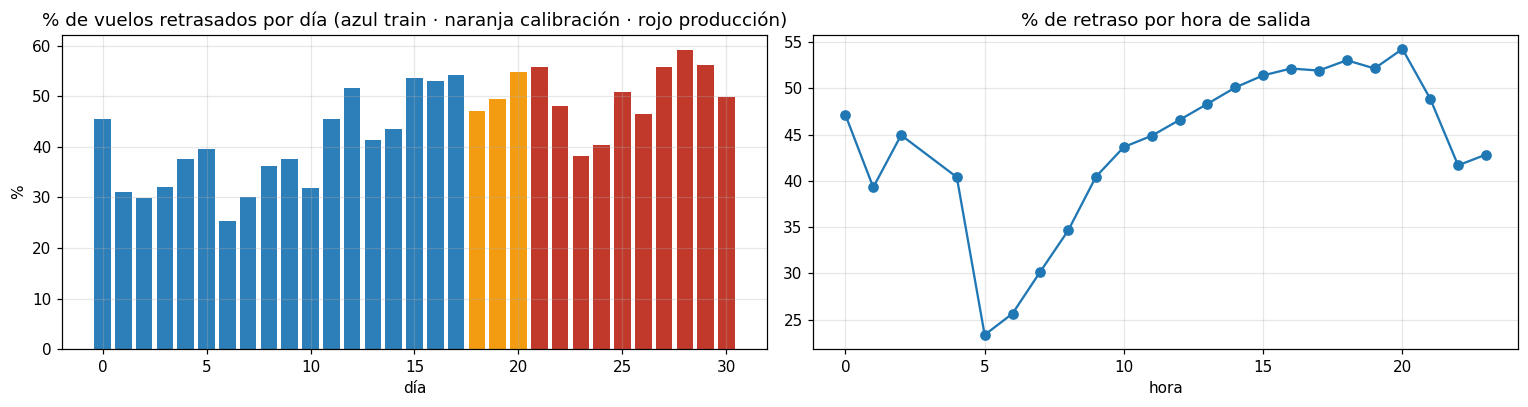

,comprobación,resultado
0,Número de días reconstruidos,31
1,Transiciones de DayOfWeek que avanzan exactame...,30 de 30
2,Descensos de 'Time' que coinciden con cambio d...,30 de 66
3,Descensos de 'Time' dentro de un día (fusión d...,36 (≈ 1.2 por día)
4,Vuelos por día (mín – máx),"14,279 – 18,585"


In [7]:
def reconstruct_days(df):
    dow = df["DayOfWeek"].to_numpy()
    starts = np.r_[0, np.flatnonzero(np.diff(dow) != 0) + 1]
    out = df.copy()
    out["day"] = np.repeat(np.arange(len(starts)), np.diff(np.r_[starts, len(df)]))
    out["row_in_day"] = out.groupby("day").cumcount()
    return out, starts

with timed("reconstruccion_de_dias"):
    data_raw, starts = reconstruct_days(raw_df)
steps = (np.diff(data_raw["DayOfWeek"].to_numpy()[starts]) % 7)
t = data_raw["Time"].to_numpy()
drops = np.flatnonzero(np.diff(t) < 0) + 1
drops_inside = np.setdiff1d(drops, starts)
checks = pd.DataFrame([
    {"comprobación": "Número de días reconstruidos", "resultado": data_raw["day"].nunique()},
    {"comprobación": "Transiciones de DayOfWeek que avanzan exactamente +1 día", "resultado": f"{(steps == 1).sum()} de {len(steps)}"},
    {"comprobación": "Descensos de 'Time' que coinciden con cambio de día", "resultado": f"{len(drops) - len(drops_inside)} de {len(drops)}"},
    {"comprobación": "Descensos de 'Time' dentro de un día (fusión de dos listados)", "resultado": f"{len(drops_inside)} (≈ {len(drops_inside) / data_raw['day'].nunique():.1f} por día)"},
    {"comprobación": "Vuelos por día (mín – máx)", "resultado": f"{data_raw.groupby('day').size().min():,} – {data_raw.groupby('day').size().max():,}"},
]).astype({"resultado": str})
daily = data_raw.groupby("day").agg(vuelos=("Delay", "size"), tasa_retraso=("Delay", "mean"), dia_semana=("DayOfWeek", "first"))
hourly = data_raw.assign(hora=data_raw["Time"] // 60).groupby("hora")["Delay"].agg(["size", "mean"])
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].bar(daily.index, 100 * daily["tasa_retraso"], color=np.where(daily.index >= CONFIG["train_days"] + CONFIG["cal_days"], "#c0392b",
                                                                   np.where(daily.index >= CONFIG["train_days"], "#f39c12", "#2c7fb8")))
ax[0].set_title("% de vuelos retrasados por día (azul train · naranja calibración · rojo producción)")
ax[0].set_xlabel("día")
ax[0].set_ylabel("%")
ax[1].plot(hourly.index, 100 * hourly["mean"], "o-")
ax[1].set_title("% de retraso por hora de salida")
ax[1].set_xlabel("hora")
plt.tight_layout()
plt.show()
checks

**El error de TT1, cuantificado:**
- Una ventana de 500 filas consecutivas equivale a ~1 hora de un solo día: un solo `DayOfWeek` y una franja estrecha de `Time`.
- Al compararla con train mediante PSI, el monitor "detecta" el reloj y el calendario, no un drift.
- La celda reproduce el esquema de TT1 (ventanas consecutivas, `DayOfWeek` incluido) y lo contrasta con el de TT2: vuelos al azar dentro del día y el calendario excluido del PSI.

In [8]:
ref_cols = MONITOR_FEATURES + ["DayOfWeek"]
tr_mask = data_raw["day"] < CONFIG["train_days"]
psi_tt1 = PSIReference(n_bins=CONFIG["psi_bins"]).fit(monitor_frame(data_raw[tr_mask]).assign(DayOfWeek=data_raw.loc[tr_mask, "DayOfWeek"].astype(str)))
prod_rows = data_raw.index[data_raw["day"] >= CONFIG["train_days"] + CONFIG["cal_days"]].to_numpy()
rng_demo = np.random.default_rng(SEED)
psi_tt2 = PSIReference(n_bins=CONFIG["psi_bins"]).fit(monitor_frame(data_raw[tr_mask]))
rows = []
for scheme in ["TT1 · 500 vuelos consecutivos, con DayOfWeek", "TT2 · 500 vuelos al azar dentro del día, sin calendario"]:
    for w in range(10):
        start = prod_rows[0] + w * 5000
        if scheme.startswith("TT1"):
            idx = np.arange(start, start + CONFIG["tt1_window"])
            w_df = data_raw.loc[idx]
            psi = psi_tt1.transform(monitor_frame(w_df).assign(DayOfWeek=w_df["DayOfWeek"].astype(str)))
        else:
            day_rows = data_raw.index[data_raw["day"] == data_raw.at[start, "day"]].to_numpy()
            w_df = data_raw.loc[rng_demo.choice(day_rows, CONFIG["tt1_window"], replace=False)]
            psi = psi_tt2.transform(monitor_frame(w_df))
        rows.append({"esquema": scheme, "ventana": w, "PSI_máx": psi.max(), "variable_dominante": psi.idxmax(),
                     "minutos_cubiertos": int(w_df["Time"].max() - w_df["Time"].min())})
tt1_demo = pd.DataFrame(rows)
print(f"Umbral clásico de alerta crítica: 0.20. Distribución nula empírica para 500 vuelos: ver §2.6.")
tt1_demo.groupby("esquema").agg(PSI_máx_medio=("PSI_máx", "mean"), minutos_cubiertos_medio=("minutos_cubiertos", "mean"),
                                variable_dominante=("variable_dominante", lambda s: s.mode().iloc[0])).round(3)

Umbral clásico de alerta crítica: 0.20. Distribución nula empírica para 500 vuelos: ver §2.6.


,PSI_máx_medio,minutos_cubiertos_medio,variable_dominante
esquema,,,
"TT1 · 500 vuelos consecutivos, con DayOfWeek",8.298,58.4,Time
"TT2 · 500 vuelos al azar dentro del día, sin calendario",0.077,1271.0,AirportFrom


### 1.7 Requisitos de un dataset candidato (observación 4)
`validate_dataset()` convierte los criterios de selección en pruebas medibles; es la misma función para los tres datasets del proyecto.

| Requisito | Criterio verificable |
|---|---|
| R1 | Objetivo binario. |
| R2 | Eje temporal con ≥ 3 periodos. |
| R3 | Orden independiente de la etiqueta dentro del periodo. |
| R4 | Tamaño suficiente para ≥ 20 bloques. |
| R5–R6 | Positivos suficientes. |
| R7 | Faltantes acotados. |
| R8 | Pocos duplicados. |
| R9 | Evidencia de no estacionariedad. |
| R10 | Sin identificadores ni fugas. |

**Corrección aplicada en TT2:**
- La unidad de decisión es el **día completo**.
- Cualquier sub-bloque dentro de un día se toma en orden aleatorio (con semilla).
- `Flight` se declara identificador: solo sirve como llave del historial.

In [9]:
def runs_test_z(seq):
    """Prueba de rachas de Wald–Wolfowitz para una secuencia binaria (z ≈ 0 si el orden es aleatorio)."""
    s = np.asarray(seq).astype(int)
    n1, n = s.sum(), len(s)
    n0 = n - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    runs = 1 + np.count_nonzero(np.diff(s))
    mu = 2 * n1 * n0 / n + 1
    var = 2 * n1 * n0 * (2 * n1 * n0 - n) / (n ** 2 * (n - 1))
    return (runs - mu) / np.sqrt(var)

def validate_dataset(df, target, period_col, order_col, features, id_cols=(), block_size=2000, min_blocks=20,
                     min_pos_block=25, min_pos_buffer=100, recal_buffer=2000, prod_frac=0.30,
                     max_missing=0.60, warn_missing=0.30, max_dup=0.01):
    """Checklist cuantitativo de idoneidad para estudiar calibration drift (✅ · ⚠️ · ❌)."""
    rows = []

    def add(req, crit, val, ok, warn=False):
        rows.append({"requisito": req, "criterio": crit, "valor": val, "estado": ("⚠️" if warn else "✅") if ok else "❌"})

    y = df[target]
    add("R1 Objetivo binario", "valores ⊆ {0,1}", str(sorted(y.unique().tolist())), set(y.unique()) <= {0, 1})
    n_per = df[period_col].nunique()
    add("R2 Eje temporal", "≥ 3 periodos ordenables", f"{n_per} periodos", n_per >= 3)
    zmax = np.nanmax([abs(runs_test_z(g.sort_values(order_col)[target])) for _, g in df.groupby(period_col)])
    add("R3 Orden independiente de la etiqueta", "|z| de rachas < 3 en cada periodo", f"máx |z| = {zmax:.1f}", zmax < 3)
    n_prod = int(len(df) * prod_frac)
    add("R4 Tamaño de producción", f"≥ {min_blocks} bloques de {block_size}", f"{n_prod // block_size} bloques", n_prod // block_size >= min_blocks)
    prev_prod = df.sort_values([period_col, order_col])[target].iloc[-n_prod:].mean()
    add("R5 Positivos por bloque", f"≥ {min_pos_block} esperados", f"{prev_prod * block_size:.0f}", prev_prod * block_size >= min_pos_block)
    add("R6 Positivos en buffer de recalibración", f"≥ {min_pos_buffer} en {recal_buffer} filas", f"{prev_prod * recal_buffer:.0f}",
        prev_prod * recal_buffer >= min_pos_buffer)
    miss = df[features].isna().mean()
    add("R7 Faltantes por variable", f"máx ≤ {max_missing:.0%} (⚠️ si > {warn_missing:.0%})", f"{miss.max():.1%}",
        miss.max() <= max_missing, warn=miss.max() > warn_missing)
    dup = df.duplicated(subset=features + [period_col]).mean()
    add("R8 Duplicados exactos (mismo día)", f"≤ {max_dup:.0%}", f"{dup:.3%}", dup <= max_dup)
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(df[period_col], df[target]))
    add("R9 Evidencia de no estacionariedad", "χ² de prevalencia entre periodos, p < 0.05", f"p = {p:.1e}", p < 0.05)
    leaked = [c for c in id_cols if c in features]
    add("R10 Sin identificadores ni fugas", "ninguna columna ID o post-desenlace entre las variables", ", ".join(leaked) or "ninguna", not leaked)
    return pd.DataFrame(rows)

rng_ord = np.random.default_rng(SEED)
data = data_raw.copy()
data["order_in_day"] = data.groupby("day")["row_in_day"].transform(lambda s: rng_ord.permutation(len(s)))
VALIDATION_KW = dict(target="Delay", period_col="day", id_cols=("Flight", "row_in_day", "order_in_day", "day"),
                     block_size=2000, recal_buffer=2000,
                     prod_frac=1 - (CONFIG["train_days"] + CONFIG["cal_days"]) / data["day"].nunique())
with timed("validacion_dataset"):
    validation_raw = validate_dataset(data, order_col="row_in_day", features=RAW_COLUMNS, **VALIDATION_KW)
    validation_fixed = validate_dataset(data, order_col="order_in_day", features=[c for c in RAW_COLUMNS if c != "Flight"], **VALIDATION_KW)
validation = validation_raw[["requisito", "criterio"]].assign(
    **{"TT1 · orden original, Flight como variable": validation_raw["valor"] + "  " + validation_raw["estado"],
       "TT2 · corregido": validation_fixed["valor"] + "  " + validation_fixed["estado"]})
validation

⏱  validacion_dataset: 1.030 s  (RSS 507 MB)


,requisito,criterio,"TT1 · orden original, Flight como variable",TT2 · corregido
0,R1 Objetivo binario,"valores ⊆ {0,1}","[0, 1] ✅","[0, 1] ✅"
1,R2 Eje temporal,≥ 3 periodos ordenables,31 periodos ✅,31 periodos ✅
2,R3 Orden independiente de la etiqueta,|z| de rachas < 3 en cada periodo,máx |z| = 21.9 ❌,máx |z| = 1.4 ✅
3,R4 Tamaño de producción,≥ 20 bloques de 2000,86 bloques ✅,86 bloques ✅
4,R5 Positivos por bloque,≥ 25 esperados,1011 ✅,1011 ✅
5,R6 Positivos en buffer de recalibración,≥ 100 en 2000 filas,1011 ✅,1011 ✅
6,R7 Faltantes por variable,máx ≤ 60% (⚠️ si > 30%),0.0% ✅,0.0% ✅
7,R8 Duplicados exactos (mismo día),≤ 1%,0.000% ✅,0.002% ✅
8,R9 Evidencia de no estacionariedad,"χ² de prevalencia entre periodos, p < 0.05",p = 0.0e+00 ✅,p = 0.0e+00 ✅
9,R10 Sin identificadores ni fugas,ninguna columna ID o post-desenlace entre las ...,Flight ❌,ninguna ✅


## 2. Preprocesamiento avanzado y feature engineering
### 2.1 Partición temporal alineada a días completos
El protocolo fija 60/10/30. En Airline se respeta **por días completos**, para no partir un día entre train y producción:
- **Train:** días 0–17 (≈ 58 %).
- **Calibración:** días 18–20 (≈ 10 %).
- **Producción:** días 21–30 (≈ 32 %).

La validación interna del modelo usa los últimos 3 días de train.

In [10]:
n_days = data["day"].nunique()
d_tr, d_ca = CONFIG["train_days"], CONFIG["train_days"] + CONFIG["cal_days"]
data["split"] = np.where(data["day"] < d_tr, "train", np.where(data["day"] < d_ca, "calibration", "production"))
idx_tr = data.index[data["split"] == "train"].to_numpy()
idx_ca = data.index[data["split"] == "calibration"].to_numpy()
idx_pr = data.index[data["split"] == "production"].to_numpy()
y_all = data["Delay"].to_numpy()
y_tr, y_ca, y_pr = y_all[idx_tr], y_all[idx_ca], y_all[idx_pr]
split_summary = (data.groupby("split").agg(dias=("day", lambda s: f"{s.min()}–{s.max()}"), vuelos=("Delay", "size"),
                                           tasa_retraso=("Delay", "mean")).loc[["train", "calibration", "production"]])
split_summary["porcentaje"] = 100 * split_summary["vuelos"] / len(data)
split_summary.round(3)

,dias,vuelos,tasa_retraso,porcentaje
split,,,,
train,0–17,311213,0.402,57.698
calibration,18–20,54190,0.505,10.047
production,21–30,173980,0.505,32.255


### 2.2 Variables categóricas: cardinalidad, categorías raras y no vistas
Los vocabularios se congelan con **train** (en TT1 el `LabelEncoder` se ajustó con todo el dataset, una fuga de información). En producción, una categoría no vista se trata como "desconocida".

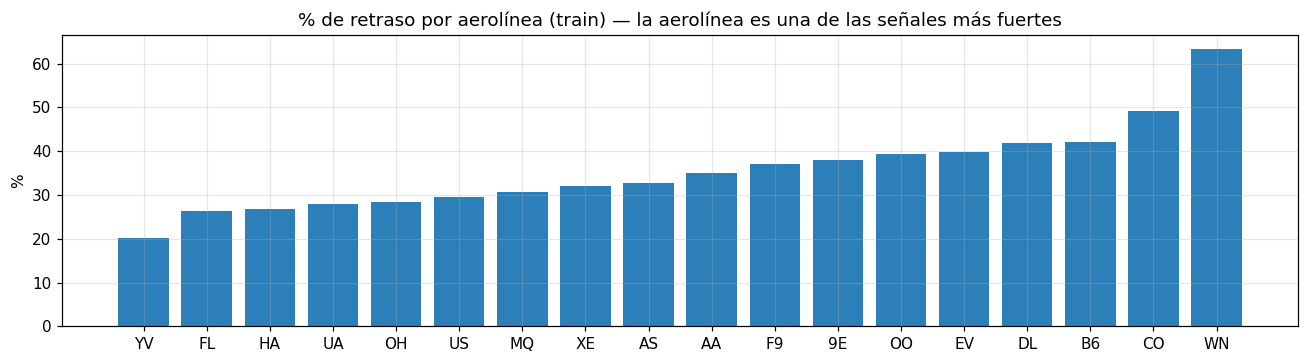

'Flight' tiene 6,585 números distintos y 18,170 combinaciones aerolínea+número:
es un IDENTIFICADOR de un servicio que se repite a diario, no una magnitud. Se usa solo como llave del historial (§2.3).


,variable,categorías_en_train,raras_(<200 vuelos en train),vuelos_en_categorías_raras_%,vuelos_de_producción_con_categoría_no_vista_%
0,Airline,18,0,0.000,0.000
1,AirportFrom,292,143,3.715,0.006
2,AirportTo,292,143,3.700,0.006


In [11]:
cat_rows = []
for c in CAT_FEATURES:
    vc = data.loc[idx_tr, c].value_counts()
    cat_rows.append({"variable": c, "categorías_en_train": len(vc), "raras_(<200 vuelos en train)": int((vc < 200).sum()),
                     "vuelos_en_categorías_raras_%": 100 * vc[vc < 200].sum() / len(idx_tr),
                     "vuelos_de_producción_con_categoría_no_vista_%": 100 * (~data.loc[idx_pr, c].isin(vc.index)).mean()})
cat_profile = pd.DataFrame(cat_rows)
airline_rate = data.loc[idx_tr].groupby("Airline")["Delay"].agg(["size", "mean"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(airline_rate.index, 100 * airline_rate["mean"], color="#2c7fb8")
ax.set_title("% de retraso por aerolínea (train) — la aerolínea es una de las señales más fuertes")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()
print(f"'Flight' tiene {data['Flight'].nunique():,} números distintos y {data.groupby(['Airline', 'Flight']).ngroups:,} combinaciones aerolínea+número:")
print("es un IDENTIFICADOR de un servicio que se repite a diario, no una magnitud. Se usa solo como llave del historial (§2.3).")
cat_profile.round(3)

### 2.3 Feature engineering: historial causal de retrasos (sin fuga de información)
**Idea en lenguaje llano:** el mejor indicio de que el vuelo 269 de CO se retrase hoy es cuántas veces se ha retrasado antes y qué tan mal le fue ayer a su aeropuerto.

**Variables (para cada llave: vuelo, ruta, aeropuerto de origen, de destino y aerolínea):**
- `h_*` — tasa histórica de retraso con **suavizado bayesiano**: (retrasos + m·prior)/(vuelos + m), m = 20. Una llave nueva empieza en la tasa global y se aleja conforme acumula historia.
- `p_*` — tasa del **día anterior**: capta rachas de clima y congestión.
- `n_fl`, `n_route` — cuánta historia hay (log): le dice al modelo qué tan confiable es `h_*`.
- `prev_day_rate` — tasa global de retraso del día anterior.
- `sin_t`, `cos_t` — hora de salida cíclica: las 23:59 quedan junto a las 00:00.

**Garantía anti-fuga:** para un vuelo del día *d* solo se usan etiquetas de los días < *d*, que en operación real ya se conocen. `HistoryStore` reproduce exactamente el mismo cálculo en línea para el dashboard; la celda verifica que ambas rutas den valores idénticos.

In [12]:
PRIOR = float(y_tr.mean())
with timed("historial_causal_batch"):
    LAGS = causal_lags(data, prior=PRIOR, m=CONFIG["history_smoothing_m"])
with timed("historial_en_linea_HistoryStore"):
    last_day = int(data["day"].max())
    hs_check = HistoryStore(PRIOR, CONFIG["history_smoothing_m"]).fit(data[data["day"] < last_day])
    online = hs_check.lookup(data[data["day"] == last_day])
equal = np.allclose(online.to_numpy(), LAGS[data["day"] == last_day].to_numpy())
print(f"Equivalencia batch ↔ en línea para el día {last_day}: {equal}")

featurizer = AirlineFeaturizer().fit(data.loc[idx_tr])
with timed("construccion_variables"):
    X_all = featurizer.transform(data, LAGS)
X_tr, X_ca, X_pr = X_all.loc[idx_tr], X_all.loc[idx_ca], X_all.loc[idx_pr]
auc_lag = pd.Series({c: roc_auc_score(y_ca, X_ca[c]) for c in LAG_FEATURES + ["sin_t", "cos_t", "Length"]})
lag_tbl = pd.DataFrame({"AUC_univariada_calibración": np.maximum(auc_lag, 1 - auc_lag), "descripción": pd.Series(FEATURE_LABELS)}).dropna()
lag_tbl.sort_values("AUC_univariada_calibración", ascending=False).round(3)

⏱  historial_causal_batch: 2.607 s  (RSS 662 MB)
⏱  historial_en_linea_HistoryStore: 1.353 s  (RSS 706 MB)
Equivalencia batch ↔ en línea para el día 30: True
⏱  construccion_variables: 0.395 s  (RSS 763 MB)


,AUC_univariada_calibración,descripción
h_fl,0.706,Tasa histórica de retraso · vuelo (aerolínea +...
h_route,0.674,Tasa histórica de retraso · ruta (origen → des...
p_airline,0.664,Tasa de retraso del día anterior · aerolínea
h_airline,0.662,Tasa histórica de retraso · aerolínea
p_route,0.644,Tasa de retraso del día anterior · ruta (orige...
p_fl,0.639,Tasa de retraso del día anterior · vuelo (aero...
p_orig,0.631,Tasa de retraso del día anterior · aeropuerto ...
h_orig,0.628,Tasa histórica de retraso · aeropuerto de origen
p_dest,0.611,Tasa de retraso del día anterior · aeropuerto ...
h_dest,0.609,Tasa histórica de retraso · aeropuerto de destino


### 2.4 Estrategia de codificación, imputación y desbalance

**Codificación categórica: cada modelo recibe lo que su matemática requiere**
- *XGBoost*: **categorías nativas** (`enable_categorical`). Cada división del árbol agrupa aeropuertos con comportamiento similar, sin inventar un orden artificial ni crear cientos de columnas.
- *Regresión logística*:
  - **One-hot** con `min_frequency = 200`: los aeropuertos con menos de 200 vuelos en train se agrupan en "infrecuente".
  - Las categorías no vistas caen en ese mismo grupo.
  - Las tasas históricas entran en escala logit.
- En ambos casos, `Flight` no entra como número.

**Faltantes:** el dataset no tiene nulos. Los únicos faltantes posibles son categorías no vistas en producción: NaN nativo en XGBoost e "infrecuente" en la LR.

**Desbalance:**
- Es leve (≈ 45 % de retrasos), así que no se aplican pesos ni remuestreo: solo distorsionarían las probabilidades (ablación §3.6).
- El umbral de decisión se optimiza por F1 en el split de calibración (§4.5).

In [13]:
print(make_lr_pipeline(C=0.1, min_frequency=CONFIG["onehot_min_frequency"]))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=200),
                                                  ['Airline', 'AirportFrom',
                                                   'AirportTo', 'DayOfWeek']),
                                                 ('num', StandardScaler(),
                                                  ['Length', 'sin_t', 'cos_t']),
                                                 ('rates',
                                                  Pipeline(steps=[('logit',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function _logit at 0x782fd53bea20>)),
                                   

### 2.5 ¿Análisis estático o con ajuste de dimensionalidad? (observación 6)
**Postura del proyecto:**
- El análisis exploratorio es **estático** (una vez, sobre el histórico). El monitoreo es **dinámico** (día por día).
- El **esquema de variables se congela en cada versión del modelo**:
  - Vocabularios categóricos, grupos de categorías raras y lista de variables se ajustan solo con train.
  - Se re-estiman únicamente al reentrenar, con versión registrada.
- Lo que sí se actualiza a diario son los **valores** del historial (`HistoryStore.update`), no el esquema.

**En Airline el ajuste de dimensionalidad va en dirección opuesta a Polish:**
- Hay solo 7 atributos crudos, así que no se reduce: se **expande** con variables informativas (historial y hora cíclica).
- Donde sí se controla la dimensión es en la LR: la agrupación de categorías raras reduce el one-hot de cientos de columnas a las que tienen soporte estadístico.
- La ablación §3.6 mide el efecto.

In [14]:
dims = []
for mf in [None, CONFIG["onehot_min_frequency"]]:
    prep = make_lr_pipeline(min_frequency=mf)[:-1].fit(X_tr)
    dims.append({"one-hot": "sin agrupar" if mf is None else f"min_frequency = {mf}", "columnas_totales_LR": len(prep.get_feature_names_out())})
pd.DataFrame(dims)

,one-hot,columnas_totales_LR
0,sin agrupar,625
1,min_frequency = 200,341


### 2.6 Population Stability Index (PSI) a lo largo de los 31 días
PSI = Σᵢ (qᵢ − pᵢ)·ln(qᵢ / pᵢ), donde *p* es la distribución de referencia y *q* la observada.
- **Variables numéricas:** deciles de la referencia más un bin de faltantes.
- **Categóricas:** las 30 categorías más frecuentes, más "otras" y faltantes.

**Qué se monitorea:**
- Se vigilan las variables crudas del vuelo (aerolínea, aeropuertos, hora, duración).
- `DayOfWeek` se excluye: es calendario y cambia por diseño.

**Umbrales:** son **empíricos**, como en Polish. La referencia se ajusta con una mitad aleatoria de train y la distribución nula de PSI_máx se estima con muestras de la otra mitad, para tamaños de 500, 2 000 y ≈ 17 000 vuelos (un día).

⏱  psi_por_dia: 0.547 s  (RSS 817 MB)


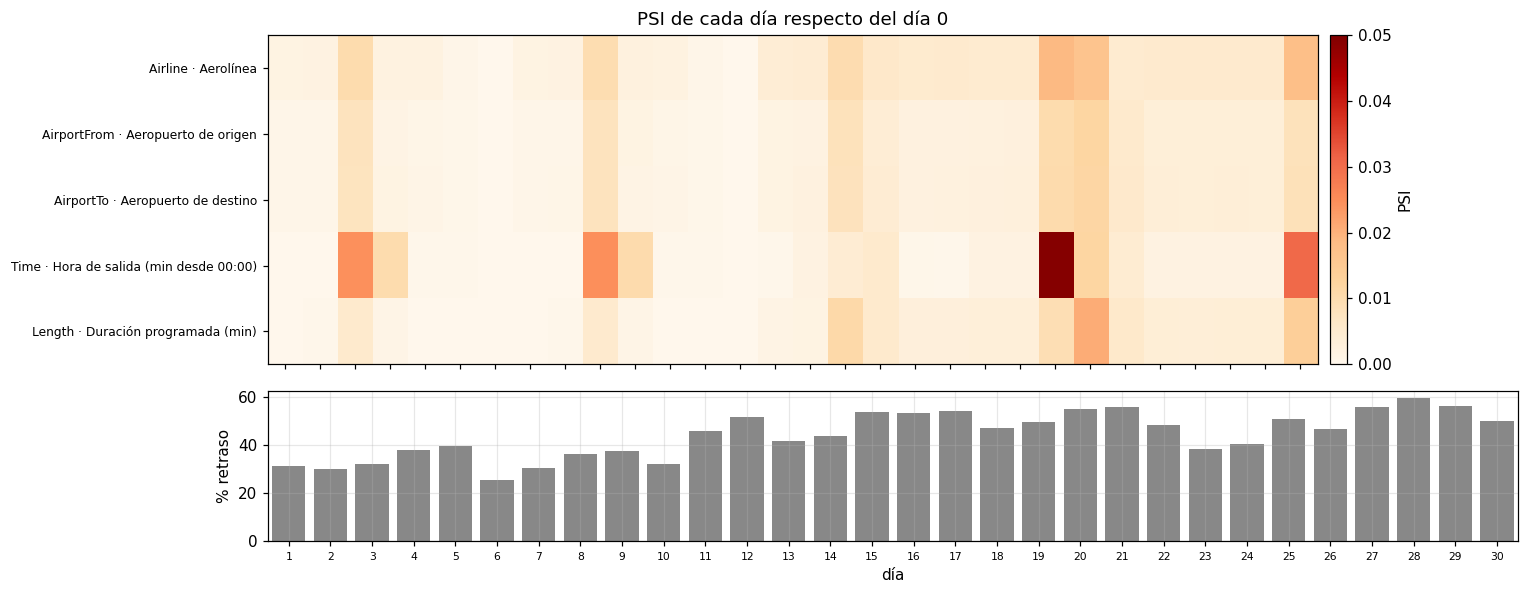

PSI máximo entre días (vs día 0): 0.0492 · tasa de retraso diaria: 25.4% – 59.2%


In [15]:
with timed("psi_por_dia"):
    ref_d0 = PSIReference(n_bins=CONFIG["psi_bins"], max_categories=CONFIG["psi_max_categories"]).fit(monitor_frame(data[data["day"] == 0]))
    psi_days = pd.DataFrame({d: ref_d0.transform(monitor_frame(g)) for d, g in data.groupby("day") if d > 0})
fig, ax = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
im = ax[0].imshow(psi_days.to_numpy(), cmap="OrRd", aspect="auto", vmin=0, vmax=max(0.05, psi_days.to_numpy().max()))
ax[0].set_yticks(range(len(psi_days)))
ax[0].set_yticklabels([f"{c} · {FEATURE_LABELS[c]}" for c in psi_days.index], fontsize=8)
ax[0].set_title("PSI de cada día respecto del día 0")
ax[0].grid(False)
plt.colorbar(im, ax=ax[0], label="PSI", pad=0.01)
ax[1].bar(range(psi_days.shape[1]), 100 * daily.loc[psi_days.columns, "tasa_retraso"].to_numpy(), color="#888")
ax[1].set_ylabel("% retraso")
ax[1].set_xticks(range(psi_days.shape[1]))
ax[1].set_xticklabels(psi_days.columns, fontsize=7)
ax[1].set_xlabel("día")
plt.tight_layout()
plt.show()
print(f"PSI máximo entre días (vs día 0): {psi_days.to_numpy().max():.4f} · tasa de retraso diaria: "
      f"{daily['tasa_retraso'].min():.1%} – {daily['tasa_retraso'].max():.1%}")

In [16]:
with timed("psi_referencia_train_y_umbrales_nulos"):
    psi_train_ref, null_thr = fit_psi_monitor(monitor_frame(data.loc[idx_tr]), CONFIG["psi_null_sizes"], B=CONFIG["psi_null_B"],
                                               seed=SEED, n_bins=CONFIG["psi_bins"], max_categories=CONFIG["psi_max_categories"])
    psi_null = pd.DataFrame([{"n": n_, **v} for n_, v in null_thr.items()])
    psi_splits = pd.DataFrame({"train→calibración": psi_train_ref.transform(monitor_frame(data.loc[idx_ca])),
                               "train→producción": psi_train_ref.transform(monitor_frame(data.loc[idx_pr]))})
print("PSI por variable respecto de train:")
print(psi_splits.round(4).to_string())
print("\nUmbrales empíricos de PSI_máx (5 variables) sin drift, según tamaño de muestra:")
psi_null.round(4)

⏱  psi_referencia_train_y_umbrales_nulos: 5.188 s  (RSS 817 MB)
PSI por variable respecto de train:
             train→calibración  train→producción
Airline                 0.0021            0.0027
AirportFrom             0.0011            0.0020
AirportTo               0.0009            0.0017
Time                    0.0015            0.0010
Length                  0.0016            0.0029

Umbrales empíricos de PSI_máx (5 variables) sin drift, según tamaño de muestra:


,n,media,p95,p99
0,500,0.0754,0.1099,0.1260
1,1000,0.0349,0.0492,0.0506
2,2000,0.0177,0.0235,0.0266
3,17000,0.0024,0.0033,0.0036


**Lectura: en Airline el drift no está en *X***
- La mezcla de aerolíneas, aeropuertos, horarios y duraciones es prácticamente la misma todos los días: PSI de milésimas frente a train y ≈ 0.05 como máximo entre días.
- Lo que cambia —y mucho— es la **tasa de retraso**: el drift es de prior y de concepto (clima, congestión, efecto dominó). Ningún detector basado solo en *X* lo puede ver.
- Por eso el monitor (§4.6) se apoya en el score del modelo y, sobre todo, en una prueba de calibración con las etiquetas del día anterior.
- Esto también confirma el diagnóstico de §1.6: el 100 % de alertas de TT1 venía del reloj dentro del día, no de la población de vuelos.
- **Los umbrales dependen del tamaño de muestra.** El p99 nulo de PSI_máx es ≈ 0.13 con 500 vuelos y ≈ 0.004 con un día completo.
  - Un 0.10 fijo daría falsas alarmas con muestras chicas.
  - Con muestras de un día, ese mismo 0.10 no detectaría nada.

## 3. Modelado y justificación
### 3.1 ¿Por qué Regresión Logística como baseline y XGBoost como modelo avanzado? (observación 2)

**Regresión logística — baseline interpretable**
- Minimiza la log-verosimilitud, una *regla de puntuación propia*: bien especificada, produce probabilidades calibradas por construcción (Niculescu-Mizil & Caruana, 2005).
- Con one-hot, cada aerolínea y aeropuerto recibe un coeficiente legible ("volar desde X suma tanto al riesgo"), ideal para explicar predicciones en el dashboard.
- Se reentrena en segundos aun con ~500 mil vuelos: es la referencia de costo mínimo para las políticas.
- Es un contraste exigente: si el historial causal está bien construido, un modelo lineal ya captura buena parte de la señal.

**XGBoost — modelo avanzado**
- Es el estado del arte en datos tabulares (Grinsztajn et al., NeurIPS 2022; Chen & Guestrin, KDD 2016).
- **Soporte nativo de categóricas de alta cardinalidad**: agrupa los 293 aeropuertos por comportamiento en cada división, sin one-hot masivo ni órdenes artificiales.
- Captura interacciones que la LR no ve sin ingeniería manual (aerolínea × hora, aeropuerto × historial reciente).
- Entrena con cientos de miles de filas en segundos con el algoritmo *hist*, lo que hace viable reentrenar a diario.
- Sus contribuciones SHAP nativas (`pred_contribs`) dan explicaciones locales sin librerías extra.

**Por qué el par:** representan los dos extremos de capacidad. En Airline la señal es débil (AUC ≈ 0.7) y está dominada por el historial, así que la comparación responde si la complejidad adicional vale su costo.

**Decisiones de configuración (iguales en los tres datasets del proyecto)**
- Sin pesos de clase ni remuestreo (§2.4; demostrado en §3.6).
- XGBoost:
  - Hiperparámetros conservadores (profundidad 6, tasa 0.05, submuestreo 0.8, `min_child_weight` 20).
  - Número de árboles por *early stopping* en una validación temporal interna (días 15–17).
  - Reajuste final con todo train.
- Regresión logística: C elegido por log-loss en la misma validación interna.
- Candidatos descartados (evidencia en §3.7):
  - Random Forest: competitivo en este dataset, pero ~10× más lento de entrenar (§3.7), lo que encarece los reentrenamientos.
  - Redes neuronales: inferiores en tabular y costosas de reentrenar a diario.
  - SVM: sin probabilidades nativas y O(n²) con 300 mil filas.

### 3.2 Matrices y validación temporal interna

In [17]:
val_mask = data.loc[idx_tr, "day"].to_numpy() >= CONFIG["train_days"] - CONFIG["inner_val_days"]
idx_fit, idx_val = idx_tr[~val_mask], idx_tr[val_mask]
X_fit, y_fit = X_all.loc[idx_fit], y_all[idx_fit]
X_val, y_val = X_all.loc[idx_val], y_all[idx_val]
print(f"Ajuste: {len(idx_fit):,} vuelos (días 0–{CONFIG['train_days'] - CONFIG['inner_val_days'] - 1}, retraso {y_fit.mean():.1%}) · "
      f"Validación interna: {len(idx_val):,} vuelos (días {CONFIG['train_days'] - CONFIG['inner_val_days']}–{CONFIG['train_days'] - 1}, retraso {y_val.mean():.1%})")

Ajuste: 258,373 vuelos (días 0–14, retraso 37.4%) · Validación interna: 52,840 vuelos (días 15–17, retraso 53.6%)


### 3.3 Entrenamiento de la Regresión Logística (con medición de tiempo)

In [18]:
%%time
with timed("LR_seleccion_de_C", modelo="LR"):
    lr_search = []
    for C in CONFIG["lr_C_grid"]:
        pipe = make_lr_pipeline(C=C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_fit, y_fit)
        p = pipe.predict_proba(X_val)[:, 1]
        lr_search.append({"C": C, "LogLoss_val": log_loss(y_val, p), "AUC_val": roc_auc_score(y_val, p), "Brier_val": np.mean((p - y_val) ** 2)})
    lr_search = pd.DataFrame(lr_search)
    best_C = float(lr_search.loc[lr_search["LogLoss_val"].idxmin(), "C"])
with timed("LR_entrenamiento_final", modelo="LR"):
    lr_model = make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr)
print(f"C seleccionado: {best_C}")
display(lr_search.round(4))

⏱  LR_seleccion_de_C: 17.188 s  (RSS 1,118 MB)
⏱  LR_entrenamiento_final: 4.378 s  (RSS 964 MB)
C seleccionado: 0.01


,C,LogLoss_val,AUC_val,Brier_val
0,0.01,0.6290,0.7148,0.2198
1,0.10,0.6304,0.7137,0.2203
2,1.00,0.6310,0.7131,0.2206


CPU times: user 31.6 s, sys: 207 ms, total: 31.8 s
Wall time: 21.6 s


### 3.4 Entrenamiento de XGBoost (con medición de tiempo)

⏱  XGB_early_stopping: 22.856 s  (RSS 976 MB)
⏱  XGB_entrenamiento_final: 14.186 s  (RSS 977 MB)
Árboles seleccionados: 177 · validación interna → LogLoss 0.6570 · AUC 0.7131


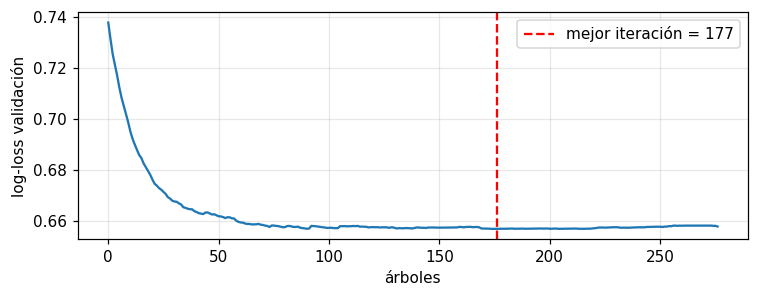

CPU times: user 1min 4s, sys: 158 ms, total: 1min 4s
Wall time: 38 s


In [19]:
%%time
with timed("XGB_early_stopping", modelo="XGB"):
    xgb_es = XGBClassifier(**XGB_PARAMS, n_estimators=CONFIG["xgb_max_rounds"],
                           early_stopping_rounds=CONFIG["xgb_early_stopping"], eval_metric="logloss")
    xgb_es.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    best_iter = int(xgb_es.best_iteration) + 1
with timed("XGB_entrenamiento_final", modelo="XGB"):
    xgb_model = XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr)
p_val = xgb_es.predict_proba(X_val)[:, 1]
print(f"Árboles seleccionados: {best_iter} · validación interna → LogLoss {log_loss(y_val, p_val):.4f} · AUC {roc_auc_score(y_val, p_val):.4f}")
curve = xgb_es.evals_result()["validation_0"]["logloss"]
plt.figure(figsize=(7, 2.8))
plt.plot(curve)
plt.axvline(best_iter - 1, color="r", ls="--", label=f"mejor iteración = {best_iter}")
plt.xlabel("árboles")
plt.ylabel("log-loss validación")
plt.legend()
plt.tight_layout()
plt.show()

### 3.5 Protocolo de medición de tiempos (observación 1)
Cada entrenamiento se repite `timing_repeats` veces y cada inferencia 5 veces. Se reporta mediana, mínimo y máximo junto con el hardware. Se incluye el costo del historial causal, que en operación se recalcula a diario.

In [20]:
def repeat_timing(fn, repeats):
    out = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        out.append(time.perf_counter() - t0)
    return np.array(out)

R_T = CONFIG["timing_repeats"]
day_last = data[data["day"] == data["day"].max()]
hs_timing = HistoryStore(PRIOR, CONFIG["history_smoothing_m"]).fit(data[data["day"] < data["day"].max()])
X_inf = X_pr.iloc[:1000]
ops = [("Historial causal (31 días, batch)", len(data), R_T, lambda: causal_lags(data, prior=PRIOR, m=CONFIG["history_smoothing_m"])),
       ("LR · entrenamiento (train completo)", len(X_tr), R_T, lambda: make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr)),
       ("XGB · entrenamiento (train completo)", len(X_tr), R_T, lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr)),
       ("Historial en línea + variables (1 día)", len(day_last), 5, lambda: featurizer.transform(day_last, hs_timing.lookup(day_last))),
       ("LR · inferencia", 1000, 5, lambda: lr_model.predict_proba(X_inf)),
       ("XGB · inferencia", 1000, 5, lambda: xgb_model.predict_proba(X_inf))]
with timed("protocolo_de_tiempos"):
    rows = []
    for name, n_rows, reps, fn in ops:
        ts = repeat_timing(fn, reps)
        rows.append({"operación": name, "filas": n_rows, "repeticiones": reps, "mediana_s": np.median(ts),
                     "min_s": ts.min(), "max_s": ts.max(), "ms_por_1000_filas": 1e6 * np.median(ts) / n_rows})
timing_protocol = pd.DataFrame(rows)
print(f"Hardware: {ENV['procesador']} · {ENV['cpus_logicos']} CPU lógicos · {ENV['ram_gb']} GB RAM · "
      f"xgboost {ENV['xgboost']} · scikit-learn {ENV['scikit-learn']} · n_jobs = {CONFIG['n_jobs']}")
timing_protocol.round(4)

⏱  protocolo_de_tiempos: 60.925 s  (RSS 1,176 MB)
Hardware: x86_64 · 2 CPU lógicos · 13.6 GB RAM · xgboost 3.4.1 · scikit-learn 1.6.1 · n_jobs = 2


,operación,filas,repeticiones,mediana_s,min_s,max_s,ms_por_1000_filas
0,"Historial causal (31 días, batch)",539383,3,1.9111,1.8735,1.9263,3.5432
1,LR · entrenamiento (train completo),311213,3,4.0656,4.0396,5.3777,13.0636
2,XGB · entrenamiento (train completo),311213,3,13.6141,13.6007,13.7743,43.7452
3,Historial en línea + variables (1 día),15363,5,0.0981,0.0947,0.1058,6.3864
4,LR · inferencia,1000,5,0.0160,0.0158,0.0164,16.0365
5,XGB · inferencia,1000,5,0.0320,0.0319,0.0375,32.0218


### 3.6 Ablaciones: evidencia de cada decisión de diseño
Cada variante cambia **una** decisión y se evalúa en el split de **calibración** (días 18–20). Producción queda intacta.

| Variante | Qué pone a prueba |
|---|---|
| TT1 (códigos + `Flight` numérico) | El costo de tratar identificadores y códigos como números. |
| Sin historial causal | El aporte del feature engineering de §2.3. |
| Pesos de clase | Su efecto sobre la calibración (prob. media vs tasa real). |
| One-hot sin agrupar | Dimensionalidad de la LR (observación 6). |
| XGBoost con categorías nativas vs códigos | La codificación categórica. |

In [21]:
def eval_row(name, y, p, secs):
    m = evaluate_probs(y, p)
    return {"variante": name, "AUC": m["AUC"], "Brier": m["Brier"], "LogLoss": m["LogLoss"], "ECE": m["ECE"],
            "prob_media": m["p_media"], "tasa_real": m["prevalencia"], "ajuste_s": secs}

def tt1_matrix(X, raw):
    """Codificación de TT1: códigos enteros de las categorías + Flight como número."""
    M = pd.DataFrame({c: X[c].cat.codes.astype(float) for c in CAT_FEATURES}, index=X.index)
    for c in ["DayOfWeek", "Time", "Length"]:
        M[c] = X[c]
    M["Flight"] = raw.loc[X.index, "Flight"].astype(float)
    return M

NO_LAG = CAT_FEATURES + ["DayOfWeek", "Time", "Length", "sin_t", "cos_t"]
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
T1_tr, T1_ca = tt1_matrix(X_tr, data), tt1_matrix(X_ca, data)
variants = [
    ("LR · TT1 (códigos escalados + Flight numérico)", lambda: Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=3000))]).fit(T1_tr, y_tr).predict_proba(T1_ca)[:, 1]),
    ("LR · one-hot sin historial", lambda: make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"], lags=False).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    ("LR · TT2 (one-hot agrupado + historial)", lambda: make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    ("LR · TT2 + class_weight='balanced'", lambda: make_lr_pipeline(C=best_C, class_weight="balanced", min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    ("LR · TT2 con one-hot sin agrupar", lambda: make_lr_pipeline(C=best_C, min_frequency=None).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    ("XGB · TT1 (códigos + Flight, 200 árboles, lr 0.1)", lambda: XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                                                                            random_state=SEED, n_jobs=CONFIG["n_jobs"]).fit(T1_tr, y_tr).predict_proba(T1_ca)[:, 1]),
    ("XGB · categorías nativas sin historial", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr[NO_LAG], y_tr).predict_proba(X_ca[NO_LAG])[:, 1]),
    ("XGB · TT2 (categorías nativas + historial)", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    (f"XGB · TT2 + scale_pos_weight = {spw:.2f}", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter, scale_pos_weight=spw).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
]
abl = []
with timed("ablaciones"):
    for name, run in variants:
        t0 = time.perf_counter()
        p = run()
        abl.append(eval_row(name, y_ca, p, time.perf_counter() - t0))
ablation = pd.DataFrame(abl)
ablation.round(4)

⏱  ablaciones: 69.155 s  (RSS 1,258 MB)


,variante,AUC,Brier,LogLoss,ECE,prob_media,tasa_real,ajuste_s
0,LR · TT1 (códigos escalados + Flight numérico),0.6311,0.2482,0.6896,0.1010,0.4047,0.5045,0.3933
1,LR · one-hot sin historial,0.6962,0.2300,0.6533,0.1036,0.4010,0.5045,2.7846
2,LR · TT2 (one-hot agrupado + historial),0.6960,0.2236,0.6387,0.0567,0.4840,0.5045,5.6441
3,LR · TT2 + class_weight='balanced',0.6960,0.2271,0.6463,0.0768,0.5633,0.5045,6.8255
4,LR · TT2 con one-hot sin agrupar,0.6960,0.2236,0.6389,0.0569,0.4828,0.5045,4.0947
5,"XGB · TT1 (códigos + Flight, 200 árboles, lr 0.1)",0.6894,0.2323,0.6585,0.1020,0.4025,0.5045,6.4797
6,XGB · categorías nativas sin historial,0.7000,0.2292,0.6523,0.1023,0.4025,0.5045,10.4265
7,XGB · TT2 (categorías nativas + historial),0.7349,0.2071,0.5987,0.0266,0.5149,0.5045,16.4663
8,XGB · TT2 + scale_pos_weight = 1.49,0.7329,0.2152,0.6172,0.0831,0.5876,0.5045,14.5075


**Lectura de las ablaciones (split de calibración):**
- **Codificación de TT1:** tratar `Flight` y los códigos de aeropuerto como números cuesta discriminación. La LR pasa de AUC ≈ 0.63 a ≈ 0.70 con one-hot; XGBoost gana con categorías nativas.
- **Historial causal, la mejora más grande:**
  - En XGBoost sube el AUC de ≈ 0.70 a ≈ 0.73 y baja el ECE de ≈ 0.10 a ≈ 0.03.
  - En la LR el AUC casi no cambia, pero la log-loss y el ECE sí mejoran: el historial corrige el **nivel** de la probabilidad.
- **Pesos de clase:** aun con un desbalance leve, desplazan la probabilidad media por encima de la tasa real y empeoran el ECE y la log-loss sin mejorar el AUC.
- **Dimensionalidad:** agrupar aeropuertos raros reduce el one-hot de la LR casi a la mitad (≈ 625 → ≈ 340 columnas) con métricas prácticamente idénticas.

### 3.7 Benchmark ampliado de candidatos (evidencia para la observación 2)
Para que la comparación sea justa y el costo acotado, todos los candidatos se entrenan con la **misma muestra aleatoria de 100 000 vuelos de train** y se evalúan en calibración. Los aeropuertos se reducen a sus 250 códigos más frecuentes para los modelos que no aceptan alta cardinalidad (HistGradientBoosting, Random Forest).

In [22]:
def ordinal_matrix(X, top=250):
    M = pd.DataFrame(index=X.index)
    for c in CAT_FEATURES:
        freq = X_tr[c].value_counts().index[:top]
        code = X[c].astype(object).map({v: i for i, v in enumerate(freq)})
        M[c] = code.fillna(top).astype(float)
    for c in [f for f in XGB_FEATURES if f not in CAT_FEATURES]:
        M[c] = X[c]
    return M

bench = []
if CONFIG["run_extended_benchmark"]:
    with timed("benchmark_ampliado"):
        rng_b = np.random.default_rng(SEED)
        sub = rng_b.choice(len(X_tr), size=min(CONFIG["benchmark_rows"], len(X_tr)), replace=False)
        Xs, ys = X_tr.iloc[sub], y_tr[sub]
        O_s, O_ca = ordinal_matrix(Xs), ordinal_matrix(X_ca)
        pre = make_lr_pipeline(min_frequency=CONFIG["onehot_min_frequency"])[:-1].fit(Xs)
        Z_s, Z_ca = pre.transform(Xs), pre.transform(X_ca)
        cat_mask = [c in CAT_FEATURES for c in O_s.columns]
        candidates = [
            ("Regresión logística (TT2)", lambda: make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(Xs, ys).predict_proba(X_ca)[:, 1]),
            ("XGBoost (TT2)", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(Xs, ys).predict_proba(X_ca)[:, 1]),
            ("HistGradientBoosting (categorías nativas)", lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, categorical_features=cat_mask,
                                                                                                early_stopping=True, random_state=SEED).fit(O_s, ys).predict_proba(O_ca)[:, 1]),
            ("Random Forest (200 árboles)", lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=CONFIG["n_jobs"],
                                                                           random_state=SEED).fit(O_s, ys).predict_proba(O_ca)[:, 1]),
            ("MLP (64-32, early stopping)", lambda: MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200,
                                                                   random_state=SEED).fit(Z_s, ys).predict_proba(Z_ca)[:, 1]),
        ]
        for name, run in candidates:
            t0 = time.perf_counter()
            p = run()
            bench.append(eval_row(name, y_ca, p, time.perf_counter() - t0))
benchmark = pd.DataFrame(bench)
benchmark.sort_values("LogLoss").round(4) if len(benchmark) else "Benchmark ampliado desactivado en CONFIG"

⏱  benchmark_ampliado: 88.112 s  (RSS 1,193 MB)


,variante,AUC,Brier,LogLoss,ECE,prob_media,tasa_real,ajuste_s
3,Random Forest (200 árboles),0.7412,0.2055,0.5953,0.0252,0.5262,0.5045,45.9246
1,XGBoost (TT2),0.7278,0.2096,0.6044,0.0312,0.5144,0.5045,5.3861
2,HistGradientBoosting (categorías nativas),0.7266,0.2107,0.6074,0.0380,0.5203,0.5045,6.7050
0,Regresión logística (TT2),0.6996,0.2215,0.6334,0.0497,0.4976,0.5045,1.3388
4,"MLP (64-32, early stopping)",0.6523,0.2472,0.7009,0.1170,0.5133,0.5045,26.3181


**Lectura del benchmark:**
- Los ensambles de árboles (XGBoost, HistGradientBoosting, Random Forest) superan claramente a la LR y a la MLP: la señal está en interacciones entre historial, aerolínea y aeropuertos.
- Random Forest queda al nivel de XGBoost o ligeramente arriba, pero tarda un orden de magnitud más en entrenar. En un proyecto donde el reentrenamiento es una política evaluada por su costo, eso pesa.
- Por eso se mantiene **XGBoost** como modelo avanzado, con Random Forest documentado como alternativa válida.
- La MLP es la peor opción: más cara que la LR y peor calibrada.

## 4. Calibración y evaluación avanzada
### 4.1 Selección del calibrador en el split de calibración
| Método | Qué hace | Cuándo conviene |
|---|---|---|
| `none` | Deja la probabilidad del modelo. | Si ya está calibrado. |
| `temperature` | σ(logit(p)/T): un parámetro, escala la confianza. | Sobre/subconfianza simétrica. No corrige cambios de tasa base. |
| `platt` | σ(a·logit(p)+b): escala **y** sesgo. | Cambios de tasa base (el drift típico de Airline). |
| `isotonic` | Función monótona no paramétrica. | Muchos datos. Aquí hay ~52 000 vuelos de calibración, así que es viable. |

**Procedimiento de elección:**
- Se elige por **log-loss con validación cruzada estratificada de 5 pliegues** dentro del split de calibración.
- Después se ajusta el calibrador elegido con todo el split.
- El modelo recomendado se escoge con el mismo criterio, **sin mirar producción**.

In [23]:
def crossfit_calibrators(p_raw, y, methods, n_splits, seed):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = {m: np.zeros_like(p_raw) for m in methods}
    for tr_i, te_i in skf.split(p_raw.reshape(-1, 1), y):
        for m in methods:
            oof[m][te_i] = make_calibrator(m).fit(p_raw[tr_i], y[tr_i]).predict(p_raw[te_i])
    rows = [{"método": m, "LogLoss": log_loss(y, oof[m]), "Brier": np.mean((oof[m] - y) ** 2),
             "ECE": ece_uniform(y, oof[m]), "ACE": airline_tt2.ace_equal_mass(y, oof[m])} for m in methods]
    return pd.DataFrame(rows), oof

MODELS = {"lr": lr_model, "xgb": xgb_model}

def raw_scores(model, X):
    return model.predict_proba(X)[:, 1]

raw_cal = {k: raw_scores(m, X_ca) for k, m in MODELS.items()}
calib_rows, OOF, CALIBRATOR, CAL_METHOD = [], {}, {}, {}
with timed("seleccion_y_ajuste_de_calibradores"):
    for kind, p in raw_cal.items():
        tbl_c, oof = crossfit_calibrators(p, y_ca, CONFIG["calib_methods"], CONFIG["calib_cv_folds"], SEED)
        tbl_c.insert(0, "modelo", kind.upper())
        calib_rows.append(tbl_c)
        CAL_METHOD[kind] = tbl_c.loc[tbl_c["LogLoss"].idxmin(), "método"]
        OOF[kind] = oof[CAL_METHOD[kind]]
        CALIBRATOR[kind] = make_calibrator(CAL_METHOD[kind]).fit(p, y_ca)
calib_sel = pd.concat(calib_rows, ignore_index=True)
cv_best = calib_sel.loc[calib_sel.groupby("modelo")["LogLoss"].idxmin()].sort_values("LogLoss")
BEST_KIND = cv_best.iloc[0]["modelo"].lower()
for k, c in CALIBRATOR.items():
    params = {a: round(getattr(c, a), 4) for a in ("T_", "a_", "b_") if hasattr(c, a)}
    print(f"{k.upper()}: calibrador elegido = {CAL_METHOD[k]} {params}")
print(f"Modelo recomendado para el dashboard: {BEST_KIND.upper()} (menor log-loss validada en el split de calibración)")
calib_sel.round(4)

⏱  seleccion_y_ajuste_de_calibradores: 2.226 s  (RSS 1,193 MB)
LR: calibrador elegido = isotonic {}
XGB: calibrador elegido = isotonic {}
Modelo recomendado para el dashboard: XGB (menor log-loss validada en el split de calibración)


,modelo,método,LogLoss,Brier,ECE,ACE
0,LR,none,0.6387,0.2236,0.0567,0.0564
1,LR,temperature,0.6288,0.2199,0.0207,0.0223
2,LR,platt,0.6283,0.2198,0.0226,0.0211
3,LR,isotonic,0.6273,0.2193,0.0013,0.0028
4,XGB,none,0.5987,0.2071,0.0266,0.0263
5,XGB,temperature,0.5972,0.2066,0.0155,0.0135
6,XGB,platt,0.5969,0.2064,0.0116,0.0110
7,XGB,isotonic,0.5968,0.2064,0.0024,0.0020


### 4.2 Evaluación en producción con intervalos de confianza (incluye KS)
Métricas sobre los 10 días de producción (≈ 160 000 vuelos), con intervalos al 95 % por bootstrap.

| Métrica | Qué mide | Ideal |
|---|---|---|
| **AUC / AP** | Capacidad de ordenar vuelos retrasados por encima de los puntuales. | 1 |
| **Brier / BSS** | Error cuadrático de la probabilidad / mejora sobre predecir siempre la tasa de train. | 0 / > 0 |
| **ECE / ACE / MCE** | Brecha probabilidad–frecuencia (bins uniformes / igual masa / peor bin). | 0 |
| **CITL / Pendiente** | Calibración en lo grande / dispersión. | 0 / 1 |
| **O/E** | Retrasos observados / esperados. | 1 |
| **KS** | Máxima separación entre las distribuciones de score de vuelos retrasados y puntuales (Kolmogorov–Smirnov). | 1 |

**Nota sobre el criterio Brier ≤ 0.20 del protocolo:**
- Con una tasa de retraso cercana al 50 %, predecir siempre la tasa base da Brier ≈ 0.25.
- Con la señal disponible (AUC ≈ 0.7), un Brier ≤ 0.20 es prácticamente inalcanzable.
- Por eso se reporta también el **Brier Skill Score**, que mide la mejora relativa.

In [24]:
def bootstrap_ci(y, p, B, seed, fns):
    rng, n_ = np.random.default_rng(seed), len(y)
    res = {k: [] for k in fns}
    for _ in range(B):
        i = rng.integers(0, n_, n_)
        for k, f in fns.items():
            res[k].append(f(y[i], p[i]))
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in res.items()}

CI_FNS = {"AUC": roc_auc_score, "Brier": lambda y, p: np.mean((p - y) ** 2), "ECE": ece_uniform}
prior_train = y_tr.mean()
PROD_PROBS = {}
for k, m in MODELS.items():
    PROD_PROBS[f"{k.upper()} · sin calibrar"] = raw_scores(m, X_pr)
    PROD_PROBS[f"{k.upper()} · calibrada ({CAL_METHOD[k]})"] = CALIBRATOR[k].predict(PROD_PROBS[f"{k.upper()} · sin calibrar"])

rows = []
with timed("evaluacion_produccion_bootstrap"):
    for name, p in PROD_PROBS.items():
        m = evaluate_probs(y_pr, p, prior=prior_train)
        ci = bootstrap_ci(y_pr, p, CONFIG["bootstrap_B"], SEED, CI_FNS)
        row = {"modelo": name}
        for k in ["AUC", "Brier", "ECE"]:
            row[k] = f"{m[k]:.4f} [{ci[k][0]:.4f}, {ci[k][1]:.4f}]"
        row.update({k: round(m[k], 4) for k in ["AP", "BSS", "LogLoss", "ACE", "MCE", "CITL", "Pendiente", "O/E", "KS"]})
        row["KS_p"] = f"{m['KS_p']:.1e}"
        rows.append(row)
metrics_production = pd.DataFrame(rows)
print(f"Producción: {len(y_pr):,} vuelos · {y_pr.mean():.1%} retrasados · tasa en train {prior_train:.1%}")
metrics_production

⏱  evaluacion_produccion_bootstrap: 39.348 s  (RSS 1,189 MB)
Producción: 173,980 vuelos · 50.5% retrasados · tasa en train 40.2%


,modelo,AUC,Brier,ECE,AP,BSS,LogLoss,ACE,MCE,CITL,Pendiente,O/E,KS,KS_p
0,LR · sin calibrar,"0.7027 [0.7003, 0.7052]","0.2205 [0.2195, 0.2214]","0.0461 [0.0438, 0.0481]",0.7187,0.1544,0.6317,0.0465,0.1295,0.0026,0.7401,1.0010,0.2915,0.0e+00
1,LR · calibrada (isotonic),"0.7025 [0.7001, 0.7050]","0.2179 [0.2172, 0.2185]","0.0177 [0.0160, 0.0201]",0.7117,0.1642,0.6262,0.0156,0.1478,-0.0601,1.0208,0.9747,0.2910,0.0e+00
2,XGB · sin calibrar,"0.7064 [0.7042, 0.7086]","0.2181 [0.2172, 0.2188]","0.0394 [0.0372, 0.0413]",0.7222,0.1636,0.6251,0.0398,0.0680,-0.0311,0.7547,0.9878,0.2940,0.0e+00
3,XGB · calibrada (isotonic),"0.7062 [0.7041, 0.7084]","0.2168 [0.2161, 0.2175]","0.0228 [0.0211, 0.0247]",0.7173,0.1683,0.6219,0.0227,0.0636,0.0214,0.8518,1.0089,0.2937,0.0e+00


**Lectura:**
- La tasa de retraso sube de ≈ 40 % en train a ≈ 50 % en calibración y producción. Aun así, sin calibrar el cociente O/E ya es ≈ 1: las variables de recencia (`p_*`, `prev_day_rate`) ajustan el nivel.
- La calibración corrige la **forma** de la curva (ECE ≈ 0.04 → ≈ 0.02, pendiente más cercana a 1) sin cambiar el AUC.
- El ECE agregado no llega a cero porque la tasa cambia día con día; de eso se ocupa §4.6.

### 4.3 Diagramas de confiabilidad y separación KS
Bins de igual masa (10 grupos con el mismo número de vuelos). Un modelo calibrado sigue la diagonal.

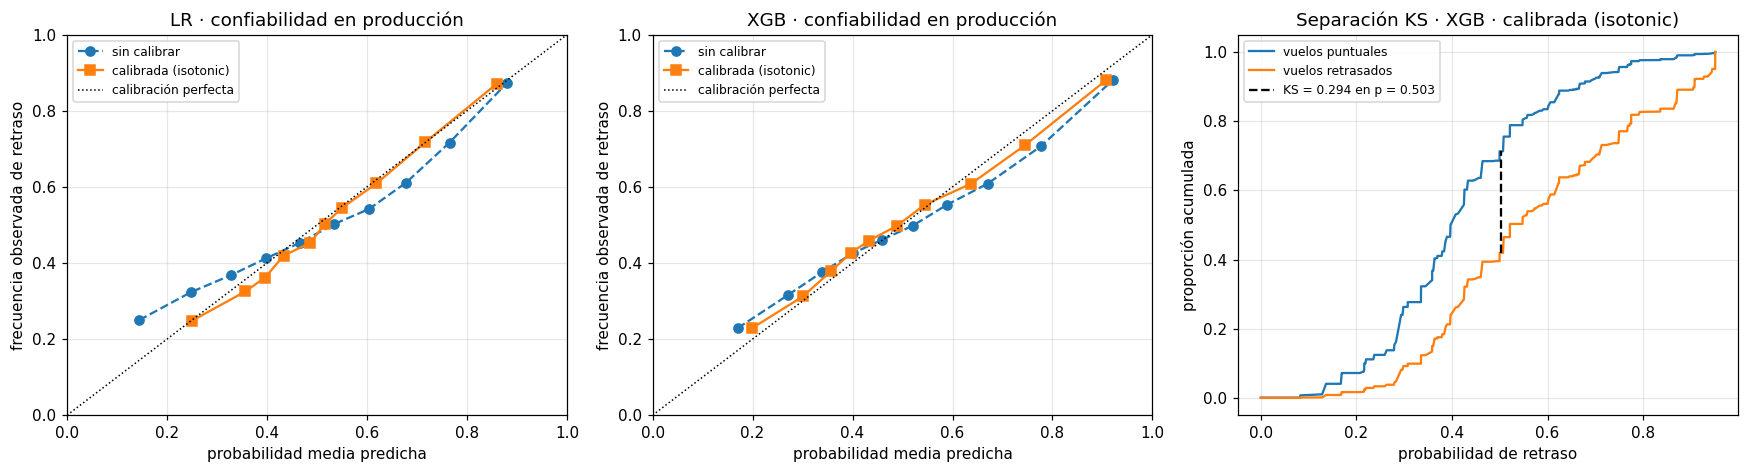

In [25]:
BEST_LABEL = f"{BEST_KIND.upper()} · calibrada ({CAL_METHOD[BEST_KIND]})"
best_p = PROD_PROBS[BEST_LABEL]
rel_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, kind in zip(axes[:2], ["lr", "xgb"]):
    for label, style in [(f"{kind.upper()} · sin calibrar", "o--"), (f"{kind.upper()} · calibrada ({CAL_METHOD[kind]})", "s-")]:
        rt = reliability_table(y_pr, PROD_PROBS[label], n_bins=10, strategy="quantile")
        rel_rows.append(rt.assign(modelo=label))
        ax.plot(rt["p_media"], rt["frecuencia_observada"], style, label=label.split(" · ")[1])
    ax.plot([0, 1], [0, 1], "k:", lw=1, label="calibración perfecta")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(f"{kind.upper()} · confiabilidad en producción")
    ax.set_xlabel("probabilidad media predicha")
    ax.set_ylabel("frecuencia observada de retraso")
    ax.legend(fontsize=8)
s1, s0 = np.sort(best_p[y_pr == 1]), np.sort(best_p[y_pr == 0])
grid_ = np.unique(np.concatenate([s0, s1]))
F1 = np.searchsorted(s1, grid_, side="right") / len(s1)
F0 = np.searchsorted(s0, grid_, side="right") / len(s0)
j = int(np.argmax(np.abs(F0 - F1)))
ax = axes[2]
ax.plot(grid_, F0, label="vuelos puntuales")
ax.plot(grid_, F1, label="vuelos retrasados")
ax.vlines(grid_[j], F1[j], F0[j], colors="k", linestyles="--", label=f"KS = {abs(F0[j] - F1[j]):.3f} en p = {grid_[j]:.3f}")
ax.set_title(f"Separación KS · {BEST_LABEL}")
ax.set_xlabel("probabilidad de retraso")
ax.set_ylabel("proporción acumulada")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
reliability_bins = pd.concat(rel_rows, ignore_index=True)

### 4.4 Piso de ruido del ECE: ¿qué valor es alcanzable?
Aun un modelo perfectamente calibrado muestra ECE > 0 en muestras finitas. Con probabilidades cercanas a 0.5 el ruido binomial es máximo. Se simula y ~ Bernoulli(p) con la distribución real de probabilidades del modelo recomendado.

In [26]:
rng_nf = np.random.default_rng(SEED)
DAY_SIZE = int(data.loc[idx_pr].groupby("day").size().median())
floor = []
for n_ in [500, 2000, DAY_SIZE, len(y_pr)]:
    e = []
    for _ in range(300):
        q = rng_nf.choice(best_p, n_, replace=True)
        e.append(ece_uniform(rng_nf.binomial(1, q), q))
    floor.append({"n": n_, "ECE_esperado_con_calibracion_perfecta": np.mean(e), "p95": np.percentile(e, 95)})
noise_floor = pd.DataFrame(floor)
print("TT1 medía el ECE en ventanas de 500 vuelos: con n = 500 el piso de ruido ya ronda el criterio de 0.05.")
noise_floor.round(4)

TT1 medía el ECE en ventanas de 500 vuelos: con n = 500 el piso de ruido ya ronda el criterio de 0.05.


,n,ECE_esperado_con_calibracion_perfecta,p95
0,500,0.0458,0.0709
1,2000,0.0227,0.0326
2,18495,0.0074,0.0111
3,173980,0.0025,0.0035


### 4.5 Umbral de decisión y bandas de riesgo para el dashboard
- **Umbral de alerta:** índice de Youden (máximo de sensibilidad + especificidad − 1), es decir, el mejor balance entre retrasos detectados y falsas alertas.
  - Con clases casi balanceadas, ambos errores pesan parecido.
  - F1 empujaría el umbral hacia abajo y marcaría la mayoría de los vuelos.
  - Se elige con las predicciones fuera de pliegue del split de calibración.
- **Bandas de riesgo** sobre la probabilidad calibrada: Bajo < 35 % ≤ Medio < 60 % ≤ Alto. La tasa observada en cada banda debe caer dentro de su rango si el modelo está calibrado.

In [27]:
def best_youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[int(np.argmax(tpr - fpr))])

THRESHOLDS = {k: best_youden_threshold(y_ca, OOF[k]) for k in MODELS}
THRESHOLD = THRESHOLDS[BEST_KIND]
yhat = (best_p >= THRESHOLD).astype(int)
print("Umbrales de Youden (calibración, fuera de pliegue): " + ", ".join(f"{k.upper()} = {v:.4f}" for k, v in THRESHOLDS.items()))
print(f"{BEST_LABEL} en producción → recall {recall_score(y_pr, yhat):.3f} · precisión {precision_score(y_pr, yhat):.3f} · "
      f"F1 {f1_score(y_pr, yhat):.3f} · exactitud balanceada {balanced_accuracy_score(y_pr, yhat):.3f} · vuelos alertados {yhat.mean():.1%}")
display(pd.DataFrame(confusion_matrix(y_pr, yhat), index=["real: puntual", "real: retrasado"], columns=["pred: puntual", "pred: retrasado"]))
cuts = CONFIG["risk_cuts"]
bands = pd.cut(best_p, [0, *cuts, 1.0 + 1e-9], labels=["Bajo", "Medio", "Alto"], right=False, include_lowest=True)
band_tbl = (pd.DataFrame({"banda": bands, "y": y_pr, "p": best_p}).groupby("banda", observed=False)
            .agg(vuelos=("y", "size"), retrasados=("y", "sum"), prob_media=("p", "mean"), tasa_observada=("y", "mean")))
band_tbl.round(4)

Umbrales de Youden (calibración, fuera de pliegue): LR = 0.5060, XGB = 0.4912
XGB · calibrada (isotonic) en producción → recall 0.605 · precisión 0.663 · F1 0.633 · exactitud balanceada 0.645 · vuelos alertados 46.1%


,pred: puntual,pred: retrasado
real: puntual,59026,27048
real: retrasado,34734,53172


,vuelos,retrasados,prob_media,tasa_observada
banda,,,,
Bajo,38624,10850,0.2582,0.2809
Medio,82512,38461,0.4480,0.4661
Alto,52844,38595,0.7606,0.7304


### 4.6 Monitoreo diario y políticas de intervención (evaluación prequential)
**En palabras simples:**
- Cada mañana el sistema conoce los vuelos programados del día (sus características, no su desenlace) y ya sabe qué pasó con los vuelos de días anteriores.
- Con eso decide si intervenir antes de emitir las probabilidades del día.
- Es la **operación real**: la unidad de decisión es el día, no una ventana de 30 minutos como en TT1.

**Señales del monitor (umbrales empíricos):**

| Señal | Qué compara | Necesita etiquetas | Nivel 1 / Nivel 2 | Rol |
|---|---|---|---|---|
| PSI del score | Scores de los vuelos de hoy vs scores de referencia | No | percentil 95 / 99 de su distribución nula | **Dispara acciones** |
| z de calibración | (retrasos observados − esperados) / √Σp(1−p) del día anterior | Sí (ayer) | percentil 95 / 99 de \|z\| sin drift (predicciones fuera de pliegue) | **Dispara acciones** |
| PSI_máx de variables | Vuelos de hoy vs train (aerolínea, aeropuertos, hora, duración) | No | percentil 95 / 99 de su distribución nula | Informativa (vista P3) |

**Políticas comparadas** (mismos días, mismas señales; el buffer son los últimos 3 días con etiqueta):
- **Sin calibrar (TT1):** probabilidad cruda.
- **Baseline calibrado:** calibrador de §4.1, fijo.
- **A · Recalibración:** ante alerta, Platt con los últimos 3 días. Tres días amortiguan el choque de un solo día.
- **B · Reentrenamiento:** ante alerta nivel 2 (enfriamiento de 2 días), reentrena con todos los días etiquetados salvo los 3 más recientes y calibra con esos 3.
- **C · Híbrida:**
  - Recalibra ante alerta.
  - Escala a reentrenamiento si la z sigue en nivel 2 tras recalibrar.
  - Reentrena por **calendario** cada 3 días (frecuencia mínima del protocolo).
- **Oráculo (in-sample):** Platt con las etiquetas del **mismo** día que evalúa (lo que hacía TT1). No es implementable; es una cota de referencia.

Tras cada intervención, la referencia del score pasa a ser el buffer reciente (**acuse de recibo**).

In [28]:
PROD_DAYS = sorted(data.loc[idx_pr, "day"].unique().tolist())
DAY_IDX = {d: data.index[data["day"] == d].to_numpy() for d in sorted(data["day"].unique())}
L_DAYS = CONFIG["recal_buffer_days"]
MON_ALL = monitor_frame(data)
FEAT_THR = null_thr[min(null_thr, key=lambda n: abs(n - DAY_SIZE))]
Z_THR = {k: z_null_thresholds(y_ca, OOF[k], n=DAY_SIZE, B=500, seed=SEED) for k in MODELS}
print(f"Tamaño típico de día: {DAY_SIZE:,} vuelos · umbrales |z| (p95 / p99): "
      + ", ".join(f"{k.upper()} = ({v['p95']:.2f}, {v['p99']:.2f})" for k, v in Z_THR.items()))
POLICIES = ["Sin calibrar (TT1)", "Baseline calibrado", "A · Recalibración", "B · Reentrenamiento", "C · Híbrida", "Oráculo (in-sample)"]

def fit_model(kind, X, y):
    if kind == "xgb":
        return XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X, y)
    return make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X, y)

def score_reference(scores, seed):
    """Referencia PSI 1-D de los scores + umbrales nulos independientes para un día típico."""
    ref, thr = fit_psi_monitor(pd.DataFrame({"score": scores}), [DAY_SIZE], B=CONFIG["psi_null_B"], seed=seed, n_bins=CONFIG["psi_bins"])
    return ref, thr[DAY_SIZE]

def level(v, thr):
    return 2 if v >= thr["p99"] else (1 if v >= thr["p95"] else 0)

def compute_signals(mon, s_raw, prev, feat_ref, feat_thr, s_ref, s_thr, z_thr):
    fpsi = float(feat_ref.transform(mon).max())
    spsi = float(s_ref.transform(pd.DataFrame({"score": s_raw})).iloc[0])
    z = np.nan if prev is None else calibration_z(*prev)
    lf, ls = level(fpsi, feat_thr), level(spsi, s_thr)
    lc = 0 if np.isnan(z) else level(abs(z), z_thr)
    return {"psi_variables_max": fpsi, "psi_score": spsi, "z_calibracion": z, "nivel_variables_info": lf,
            "nivel_score": ls, "nivel_calibracion": lc, "alerta": max(ls, lc)}

def rows_of(days):
    return np.concatenate([DAY_IDX[d] for d in days])

ISSUED = {}

def simulate(kind, policy):
    model = MODELS[kind]
    calib = IdentityCalibrator() if policy == "Sin calibrar (TT1)" else CALIBRATOR[kind]
    s_ref, s_thr = score_reference(raw_scores(model, X_ca), SEED)
    last_retrain, last_recal, prev = 0, -10 ** 6, None
    rows, all_idx, all_p = [], [], []
    for t, d in enumerate(PROD_DAYS):
        ix = DAY_IDX[d]
        Xd, yd = X_all.loc[ix], y_all[ix]
        s_raw = raw_scores(model, Xd)
        sig = compute_signals(MON_ALL.loc[ix], s_raw, prev, psi_train_ref, FEAT_THR, s_ref, s_thr, Z_THR[kind])
        want_retrain = want_recal = calendar = False
        if policy == "A · Recalibración":
            want_recal = sig["alerta"] >= 1 and t > 0
        elif policy == "B · Reentrenamiento":
            want_retrain = sig["alerta"] == 2 and t - last_retrain >= CONFIG["retrain_cooldown_days"]
        elif policy == "C · Híbrida":
            calendar = t - last_retrain >= CONFIG["calendar_K_days"]
            escalate = (sig["nivel_calibracion"] == 2 and t - last_recal <= 1
                        and t - last_retrain >= CONFIG["retrain_cooldown_days"])
            want_retrain = calendar or escalate
            want_recal = (not want_retrain) and sig["alerta"] >= 1 and t > 0
        action, secs = "ninguna", 0.0
        if want_retrain or want_recal:
            t0 = time.perf_counter()
            buf = rows_of(range(d - L_DAYS, d))
            if want_retrain:
                fit_rows = rows_of(range(0, d - L_DAYS))
                model = fit_model(kind, X_all.loc[fit_rows], y_all[fit_rows])
                action, last_retrain = ("reentrenamiento (calendario)" if calendar else "reentrenamiento"), t
            else:
                action, last_recal = "recalibración", t
            s_buf = raw_scores(model, X_all.loc[buf])
            calib = PlattScaler().fit(s_buf, y_all[buf])
            s_ref, s_thr = score_reference(s_buf, SEED + t)
            secs = time.perf_counter() - t0
            s_raw = raw_scores(model, Xd)
        p = PlattScaler().fit(s_raw, yd).predict(s_raw) if policy == "Oráculo (in-sample)" else calib.predict(s_raw)
        m = evaluate_probs(yd, p)
        rows.append({"modelo": kind.upper(), "política": policy, "día": d, "día_semana": int(data.at[ix[0], "DayOfWeek"]), **sig,
                     "acción": action, "seg_acción": secs,
                     **{k: m[k] for k in ["n", "prevalencia", "p_media", "AUC", "Brier", "ECE", "LogLoss", "O/E"]}})
        all_idx.append(ix)
        all_p.append(p)
        prev = (yd, p)
    ISSUED[(kind, policy)] = (np.concatenate(all_idx), np.concatenate(all_p))
    return pd.DataFrame(rows)

logs, summary_rows = [], []
for kind in MODELS:
    for pol in POLICIES:
        with timed("simulacion_politica", modelo=kind.upper(), politica=pol):
            log = simulate(kind, pol)
        ii, pp = ISSUED[(kind, pol)]
        pooled = evaluate_probs(y_all[ii], pp, prior=prior_train)
        logs.append(log)
        summary_rows.append({"modelo": kind.upper(), "política": pol, "AUC": pooled["AUC"], "Brier": pooled["Brier"], "BSS": pooled["BSS"],
                             "ECE": pooled["ECE"], "LogLoss": pooled["LogLoss"], "ECE_media_diaria": log["ECE"].mean(),
                             "recalibraciones": int((log["acción"] == "recalibración").sum()),
                             "reentrenamientos": int(log["acción"].str.startswith("reentrenamiento").sum()),
                             "seg_en_intervenciones": log["seg_acción"].sum(),
                             "%días_alerta≥1": 100 * (log["alerta"] >= 1).mean(), "%días_alerta=2": 100 * (log["alerta"] == 2).mean()})
policy_days = pd.concat(logs, ignore_index=True)
policy_summary = pd.DataFrame(summary_rows)
print(f"{len(PROD_DAYS)} días de producción · buffer de {L_DAYS} días · etiquetas con retraso de 1 día")
policy_summary.round(4)

Tamaño típico de día: 18,495 vuelos · umbrales |z| (p95 / p99): LR = (1.96, 2.63), XGB = (2.06, 2.54)
⏱  simulacion_politica: 5.369 s  (RSS 1,192 MB)
⏱  simulacion_politica: 4.688 s  (RSS 1,199 MB)
⏱  simulacion_politica: 9.674 s  (RSS 1,220 MB)
⏱  simulacion_politica: 32.122 s  (RSS 1,725 MB)
⏱  simulacion_politica: 37.422 s  (RSS 1,628 MB)
⏱  simulacion_politica: 6.097 s  (RSS 1,273 MB)
⏱  simulacion_politica: 6.142 s  (RSS 1,273 MB)
⏱  simulacion_politica: 6.995 s  (RSS 1,273 MB)
⏱  simulacion_politica: 15.729 s  (RSS 1,273 MB)
⏱  simulacion_politica: 106.884 s  (RSS 1,316 MB)
⏱  simulacion_politica: 116.289 s  (RSS 1,277 MB)
⏱  simulacion_politica: 7.535 s  (RSS 1,277 MB)
10 días de producción · buffer de 3 días · etiquetas con retraso de 1 día


,modelo,política,AUC,Brier,BSS,ECE,LogLoss,ECE_media_diaria,recalibraciones,reentrenamientos,seg_en_intervenciones,%días_alerta≥1,%días_alerta=2
0,LR,Sin calibrar (TT1),0.7027,0.2205,0.1544,0.0461,0.6317,0.0721,0,0,0.0000,100.0,100.0
1,LR,Baseline calibrado,0.7025,0.2179,0.1642,0.0177,0.6262,0.0641,0,0,0.0000,100.0,100.0
2,LR,A · Recalibración,0.6896,0.2231,0.1442,0.0422,0.6362,0.0955,9,0,4.0750,100.0,100.0
3,LR,B · Reentrenamiento,0.7062,0.2168,0.1685,0.0233,0.6219,0.0674,0,4,26.8883,100.0,100.0
4,LR,C · Híbrida,0.7015,0.2189,0.1605,0.0301,0.6266,0.0825,5,4,31.7700,100.0,100.0
5,LR,Oráculo (in-sample),0.7241,0.2110,0.1906,0.0139,0.6082,0.0204,0,0,0.0000,100.0,100.0
6,XGB,Sin calibrar (TT1),0.7064,0.2181,0.1636,0.0394,0.6251,0.0606,0,0,0.0000,100.0,100.0
7,XGB,Baseline calibrado,0.7062,0.2168,0.1683,0.0228,0.6219,0.0548,0,0,0.0000,100.0,100.0
8,XGB,A · Recalibración,0.7001,0.2184,0.1622,0.0134,0.6251,0.0681,9,0,7.6748,100.0,100.0
9,XGB,B · Reentrenamiento,0.7071,0.2170,0.1677,0.0204,0.6226,0.0627,0,4,99.5267,100.0,100.0


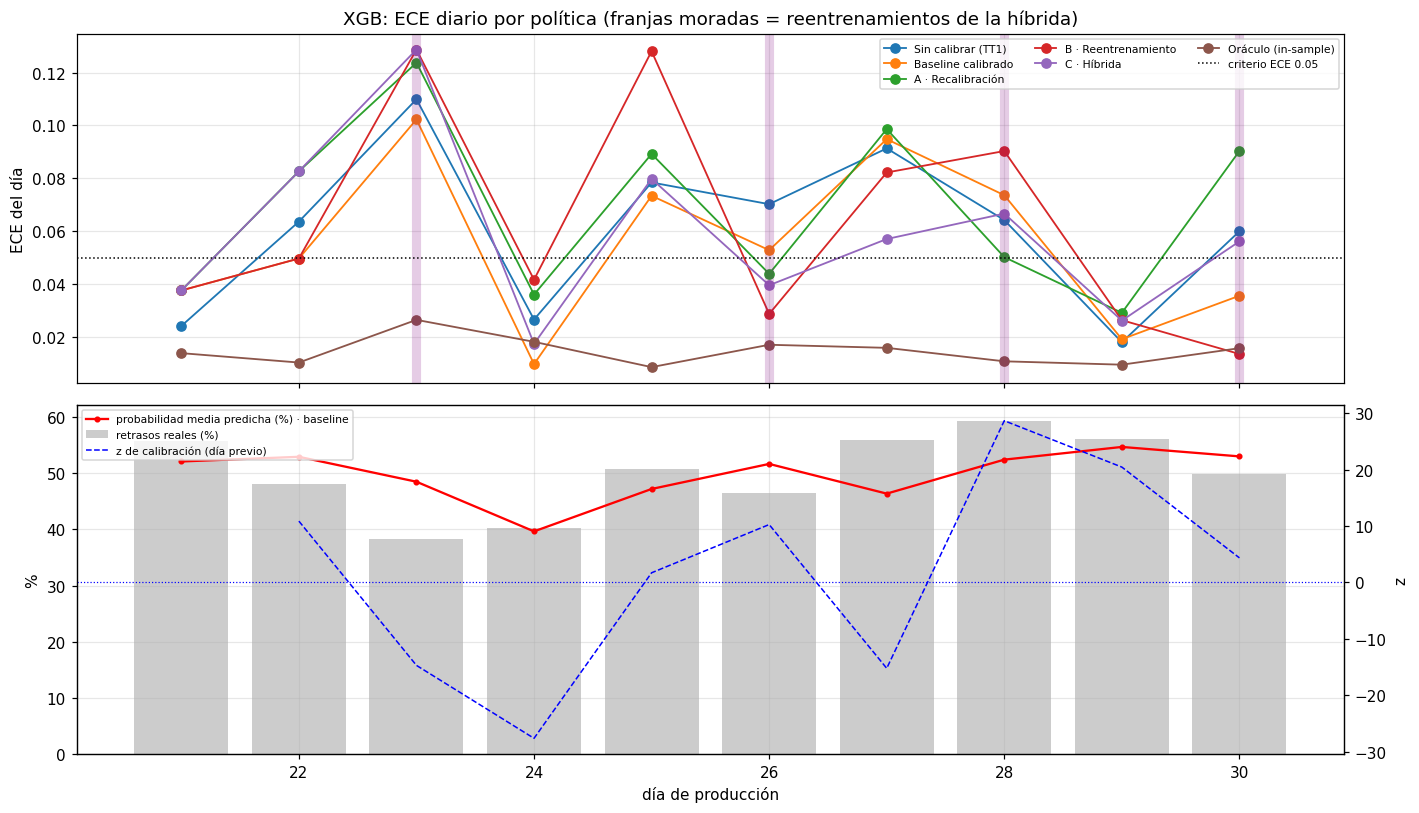

In [29]:
sub = policy_days[policy_days["modelo"] == BEST_KIND.upper()]
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for pol, g in sub.groupby("política", sort=False):
    axes[0].plot(g["día"], g["ECE"], marker="o", lw=1.2, label=pol)
for x in sub[(sub["política"] == "C · Híbrida") & sub["acción"].str.startswith("reentrenamiento")]["día"]:
    axes[0].axvline(x, color="purple", alpha=0.2, lw=6)
axes[0].axhline(0.05, color="k", ls=":", lw=1, label="criterio ECE 0.05")
axes[0].set_ylabel("ECE del día")
axes[0].set_title(f"{BEST_KIND.upper()}: ECE diario por política (franjas moradas = reentrenamientos de la híbrida)")
axes[0].legend(fontsize=7, ncol=3)
base = sub[sub["política"] == "Baseline calibrado"]
axes[1].bar(base["día"], 100 * base["prevalencia"], color="#cccccc", label="retrasos reales (%)")
axes[1].plot(base["día"], 100 * base["p_media"], "r.-", label="probabilidad media predicha (%) · baseline")
axes[1].set_ylabel("%")
axes[1].set_xlabel("día de producción")
ax2 = axes[1].twinx()
ax2.plot(base["día"], base["z_calibracion"], "b--", lw=1, label="z de calibración (día previo)")
ax2.axhline(0, color="b", ls=":", lw=0.8)
ax2.set_ylabel("z")
ax2.grid(False)
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

**Lectura de las políticas:** ver la interpretación consolidada después de §4.7.

### 4.7 Validación del monitor: falsas alarmas y latencia (criterios del protocolo)
Se construyen escenarios de **verdad conocida** a la escala del criterio del protocolo (bloques de 500 vuelos).

**Construcción de los escenarios:**
- Producción se divide al azar en dos mitades.
- Con la primera se "despliega" un sistema calibrado para esa distribución: Platt, referencias y umbrales nulos.
- Con la segunda se generan flujos de 20 bloques:
  - **Estacionario**, sin cambio: toda alerta es falsa → tasa de falsas alarmas por bloque.
  - **Label shift inyectado** desde el bloque 11: la tasa de retraso sube +5, +10 o +15 puntos porcentuales. Es el rango de variación diaria observado en §1.6.

Criterios del protocolo: falsas alarmas < 15 % y latencia ≤ 500 muestras.

In [30]:
def monitor_validation(kind, R, shifts_pp, block, n_pre=10, n_post=10, seed=SEED):
    rng = np.random.default_rng(seed)
    model = MODELS[kind]
    perm = rng.permutation(len(idx_pr))
    h_ref, h_str = perm[: len(perm) // 2], perm[len(perm) // 2:]
    s_all = raw_scores(model, X_pr)
    mon_pr = MON_ALL.loc[idx_pr]
    cal_v = PlattScaler().fit(s_all[h_ref], y_pr[h_ref])
    half = len(h_ref) // 2
    oof_v = np.zeros(len(h_ref))
    oof_v[half:] = PlattScaler().fit(s_all[h_ref[:half]], y_pr[h_ref[:half]]).predict(s_all[h_ref[half:]])
    oof_v[:half] = PlattScaler().fit(s_all[h_ref[half:]], y_pr[h_ref[half:]]).predict(s_all[h_ref[:half]])
    z_thr = z_null_thresholds(y_pr[h_ref], oof_v, n=block, B=500, seed=seed)
    f_ref, f_thr = fit_psi_monitor(mon_pr.iloc[h_ref], [block], B=CONFIG["psi_null_B"], seed=seed,
                                   n_bins=CONFIG["psi_bins"], max_categories=CONFIG["psi_max_categories"])
    f_thr = f_thr[block]
    s_ref, s_thr = fit_psi_monitor(pd.DataFrame({"score": s_all[h_ref]}), [block], B=CONFIG["psi_null_B"], seed=seed, n_bins=CONFIG["psi_bins"])
    s_thr = s_thr[block]
    pos, neg = h_str[y_pr[h_str] == 1], h_str[y_pr[h_str] == 0]
    pi = len(pos) / len(h_str)
    far_rows, lat_rows = [], []
    for shift in [0.0] + list(shifts_pp):
        for _ in range(R):
            prev, first = None, {1: None, 2: None}
            for t in range(n_pre + n_post):
                rate = pi if t < n_pre else min(pi + shift, 0.95)
                k = rng.binomial(block, rate)
                ib = np.concatenate([rng.choice(pos, k, replace=True), rng.choice(neg, block - k, replace=True)])
                sig = compute_signals(mon_pr.iloc[ib], s_all[ib], prev, f_ref, f_thr, s_ref, s_thr, z_thr)
                prev = (y_pr[ib], cal_v.predict(s_all[ib]))
                if t < n_pre or shift == 0.0:
                    if t >= 1:
                        far_rows.append({k_: sig[k_] for k_ in ["alerta", "nivel_score", "nivel_calibracion", "nivel_variables_info"]})
                else:
                    for lv in (1, 2):
                        if first[lv] is None and sig["alerta"] >= lv:
                            first[lv] = (t - n_pre + 1) * block
            if shift:
                lat_rows.append({"aumento_de_tasa_pp": int(round(100 * shift)), "latencia_N1": first[1], "latencia_N2": first[2]})
    far = pd.DataFrame(far_rows)
    far_tbl = pd.DataFrame([{"señal": name, "bloques_sin_drift": len(far), "falsas_alarmas_nivel≥1_%": 100 * (far[col] >= 1).mean(),
                             "falsas_alarmas_nivel2_%": 100 * (far[col] == 2).mean()}
                            for name, col in [("ALERTA DE ACCIÓN (score + calibración)", "alerta"), ("PSI del score", "nivel_score"),
                                              ("z de calibración", "nivel_calibracion"), ("PSI de variables (informativa)", "nivel_variables_info")]])
    lat = pd.DataFrame(lat_rows).astype(float)
    lat_tbl = lat.groupby("aumento_de_tasa_pp").agg(
        det_N2=("latencia_N2", lambda s: 100 * s.notna().mean()), latencia_mediana_N2=("latencia_N2", "median"),
        det_N1=("latencia_N1", lambda s: 100 * s.notna().mean()), latencia_mediana_N1=("latencia_N1", "median")
    ).rename(columns={"det_N2": "detección_N2_%", "det_N1": "detección_N1_%"})
    return far_tbl, lat_tbl

with timed("validacion_monitor_falsas_alarmas_latencia", modelo=BEST_KIND.upper()):
    far_tbl, lat_tbl = monitor_validation(BEST_KIND, CONFIG["monitor_validation_R"], CONFIG["label_shift_pp"], CONFIG["monitor_block"])
print("Tasa de falsas alarmas por bloque en flujos sin drift:")
display(far_tbl.round(2))
print("Latencia (vuelos observados desde el inicio del cambio hasta la alerta) y tasa de detección en 10 bloques:")
lat_tbl.round(1)

⏱  validacion_monitor_falsas_alarmas_latencia: 9.139 s  (RSS 1,277 MB)
Tasa de falsas alarmas por bloque en flujos sin drift:


,señal,bloques_sin_drift,falsas_alarmas_nivel≥1_%,falsas_alarmas_nivel2_%
0,ALERTA DE ACCIÓN (score + calibración),920,11.09,2.07
1,PSI del score,920,6.30,0.54
2,z de calibración,920,5.00,1.52
3,PSI de variables (informativa),920,4.89,2.28


Latencia (vuelos observados desde el inicio del cambio hasta la alerta) y tasa de detección en 10 bloques:


,detección_N2_%,latencia_mediana_N2,detección_N1_%,latencia_mediana_N1
aumento_de_tasa_pp,,,,
5.0,95.0,1000.0,100.0,1000.0
10.0,100.0,1000.0,100.0,1000.0
15.0,100.0,1000.0,100.0,1000.0


**Lectura consolidada (políticas y monitor):** la celda siguiente resume, con los números de esta corrida, el efecto de cada política respecto del baseline calibrado.

In [31]:
ps = policy_summary.set_index(["modelo", "política"])
effect = []
for mdl in ["LR", "XGB"]:
    b0 = ps.loc[(mdl, "Baseline calibrado")]
    for pol in ["A · Recalibración", "B · Reentrenamiento", "C · Híbrida", "Oráculo (in-sample)"]:
        r = ps.loc[(mdl, pol)]
        effect.append({"modelo": mdl, "política": pol, "ΔAUC": r["AUC"] - b0["AUC"], "ΔLogLoss": r["LogLoss"] - b0["LogLoss"],
                       "ΔECE_agregado": r["ECE"] - b0["ECE"], "ΔECE_diario_medio": r["ECE_media_diaria"] - b0["ECE_media_diaria"],
                       "intervenciones": int(r["recalibraciones"] + r["reentrenamientos"]), "segundos": r["seg_en_intervenciones"]})
effect = pd.DataFrame(effect)
best_by_model = {m: g[~g["política"].str.startswith("Oráculo")].sort_values("ΔLogLoss").iloc[0]["política"] for m, g in effect.groupby("modelo")}
best_pol = best_by_model[BEST_KIND.upper()]
far_row = far_tbl[far_tbl["señal"].str.startswith("ALERTA")].iloc[0]
print(f"Días con alerta en producción (baseline {BEST_KIND.upper()}): {ps.loc[(BEST_KIND.upper(), 'Baseline calibrado'), '%días_alerta≥1']:.0f} %")
print(f"Falsas alarmas en flujos sin drift: nivel 2 = {far_row['falsas_alarmas_nivel2_%']:.1f} % · nivel ≥ 1 = {far_row['falsas_alarmas_nivel≥1_%']:.1f} % (criterio < 15 %)")
print("Mejor política activa por log-loss agregada: " + ", ".join(f"{m} → {p}" for m, p in best_by_model.items()))
print("Efecto respecto del baseline calibrado (Δ negativo en LogLoss/ECE = mejora; Δ positivo en AUC = mejora):")
effect.round(4)

Días con alerta en producción (baseline XGB): 100 %
Falsas alarmas en flujos sin drift: nivel 2 = 2.1 % · nivel ≥ 1 = 11.1 % (criterio < 15 %)
Mejor política activa por log-loss agregada: LR → B · Reentrenamiento, XGB → C · Híbrida
Efecto respecto del baseline calibrado (Δ negativo en LogLoss/ECE = mejora; Δ positivo en AUC = mejora):


,modelo,política,ΔAUC,ΔLogLoss,ΔECE_agregado,ΔECE_diario_medio,intervenciones,segundos
0,LR,A · Recalibración,-0.0128,0.0100,0.0244,0.0315,9,4.0750
1,LR,B · Reentrenamiento,0.0038,-0.0043,0.0055,0.0033,4,26.8883
2,LR,C · Híbrida,-0.0009,0.0003,0.0124,0.0184,9,31.7700
3,LR,Oráculo (in-sample),0.0216,-0.0180,-0.0038,-0.0437,0,0.0000
4,XGB,A · Recalibración,-0.0060,0.0033,-0.0095,0.0133,9,7.6748
5,XGB,B · Reentrenamiento,0.0009,0.0007,-0.0025,0.0078,4,99.5267
6,XGB,C · Híbrida,0.0036,-0.0028,-0.0160,0.0043,9,108.5711
7,XGB,Oráculo (in-sample),0.0124,-0.0117,-0.0162,-0.0402,0,0.0000


**Cómo interpretar estos resultados en la defensa:**
- **El drift de Airline es real y de alta frecuencia.**
  - En producción el monitor alerta prácticamente todos los días; en flujos estacionarios casi no alerta (§4.7).
  - Las alertas diarias no son falsas alarmas: son choques de clima y congestión que mueven la tasa de retraso de un día a otro (25–59 %).
- **Recalibrar con los días previos persigue choques que no persisten.**
  - Puede mejorar el ECE agregado, pero no mejora el ECE diario promedio: el choque de hoy no se predice con las etiquetas de ayer.
  - En algún modelo puede incluso empeorar las métricas.
- **Reentrenar periódicamente sostiene o mejora la discriminación**, porque incorpora rutas y vuelos recientes.
  - En XGBoost la mejor política es la híbrida (reentrenamiento por calendario + recalibración): mejor AUC y log-loss, y el menor ECE agregado entre las políticas implementables.
  - En la LR la mejor es el reentrenamiento (B).
  - Ambas cuestan del orden de un minuto de cómputo en 10 días.
- **Conclusión metodológica, en contraste con Polish:** con drift de alta frecuencia la mitigación más efectiva es **proactiva**. Las variables de recencia dentro del modelo (§2.3, la mayor mejora de toda la ablación) más el reentrenamiento periódico rinden más que reaccionar a cada alerta.
- **Latencia:** la señal con etiquetas no puede alertar antes de que lleguen las etiquetas del primer bloque afectado. Con bloques de 500 y retraso de un bloque, la latencia mínima es de 1 000 vuelos, salvo que el cambio también se refleje en el score (señal sin etiquetas). En operación la unidad es el día, así que el cambio se detecta al día siguiente.
- Las cifras exactas pueden variar ligeramente con el número de CPUs de Colab.

### 4.8 Comparación TT1 vs TT2
Las cifras de TT1 provienen del notebook entregado en TT1.

**Diferencias de esquema:**
- TT1 promedió métricas en ventanas de 500 vuelos consecutivos (≈ 30 min de un día).
- TT2 reporta métricas agregadas de producción y, para comparar en igualdad de condiciones, también las **mismas ventanas de TT1** aplicadas a sus predicciones.
- La columna de intervenciones muestra el costo operativo.

In [32]:
def tt1_window_metrics(idx_issued, p_issued):
    """Promedio de ECE, Brier y AUC en ventanas de 500 filas consecutivas (esquema TT1, orden original)."""
    order = np.argsort(idx_issued)
    ii, pp = idx_issued[order], p_issued[order]
    yy = y_all[ii]
    W, S = CONFIG["tt1_window"], CONFIG["tt1_stride"]
    rows = [(ece_uniform(yy[s:s + W], pp[s:s + W]), np.mean((pp[s:s + W] - yy[s:s + W]) ** 2),
             roc_auc_score(yy[s:s + W], pp[s:s + W]) if 0 < yy[s:s + W].mean() < 1 else np.nan)
            for s in range(0, len(yy) - W + 1, S)]
    return np.nanmean(np.array(rows), axis=0)

tt1 = pd.DataFrame([
    {"comparación": "LR · AUC en calibración (sin calibrar)", "TT1": 0.6247, "TT2": roc_auc_score(y_ca, raw_cal["lr"])},
    {"comparación": "XGB · AUC en calibración (sin calibrar)", "TT1": 0.6896, "TT2": roc_auc_score(y_ca, raw_cal["xgb"])},
])
xgb_active = policy_summary[(policy_summary["modelo"] == "XGB") & policy_summary["política"].isin(["A · Recalibración", "B · Reentrenamiento", "C · Híbrida"])]
best_pol_xgb = xgb_active.set_index("política")["LogLoss"].idxmin()
rows = []
for label, pol in [("Baseline", "Baseline calibrado"), ("Mejor política activa", best_pol_xgb)]:
    e, b, a = tt1_window_metrics(*ISSUED[("xgb", pol)])
    r = policy_summary.set_index(["modelo", "política"]).loc[("XGB", pol)]
    tt1_vals = {"Baseline": (0.1222, 0.2342, 0.6689, 0), "Mejor política activa": (0.0829, 0.2287, np.nan, 807)}[label]
    rows += [{"comparación": f"XGB · producción · {label} · ECE medio en ventanas de 500", "TT1": tt1_vals[0], "TT2": e},
             {"comparación": f"XGB · producción · {label} · Brier medio en ventanas de 500", "TT1": tt1_vals[1], "TT2": b},
             {"comparación": f"XGB · producción · {label} · ECE agregado", "TT1": np.nan, "TT2": r["ECE"]},
             {"comparación": f"XGB · producción · {label} · intervenciones", "TT1": tt1_vals[3], "TT2": r["recalibraciones"] + r["reentrenamientos"]}]
    if label == "Baseline":
        rows.append({"comparación": "XGB · producción · Baseline · AUC medio en ventanas de 500", "TT1": tt1_vals[2], "TT2": a})
comparison = pd.concat([tt1, pd.DataFrame(rows)], ignore_index=True)
print(f"Mejor política activa TT2 (XGB, menor log-loss agregada): {best_pol_xgb}")
comparison.round(4)

Mejor política activa TT2 (XGB, menor log-loss agregada): C · Híbrida


,comparación,TT1,TT2
0,LR · AUC en calibración (sin calibrar),0.6247,0.6960
1,XGB · AUC en calibración (sin calibrar),0.6896,0.7349
2,XGB · producción · Baseline · ECE medio en ven...,0.1222,0.0740
3,XGB · producción · Baseline · Brier medio en v...,0.2342,0.2167
4,XGB · producción · Baseline · ECE agregado,NaN,0.0228
5,XGB · producción · Baseline · intervenciones,0.0000,0.0000
6,XGB · producción · Baseline · AUC medio en ven...,0.6689,0.6887
7,XGB · producción · Mejor política activa · ECE...,0.0829,0.0742
8,XGB · producción · Mejor política activa · Bri...,0.2287,0.2155
9,XGB · producción · Mejor política activa · ECE...,NaN,0.0068


## 5. Preparación para el dashboard (pipeline de inferencia)
### 5.1 Empaquetado del modelo, del historial y exportación de artefactos
**`bundle.joblib`** es un único objeto que el dashboard carga. Contiene:
- Los dos `DelayScorer`: modelo + esquema de variables + calibrador + umbral + bandas.
- El modelo recomendado.
- El **`HistoryStore`** con los acumulados de los 31 días: sirve para predecir el día siguiente y se actualiza con `update()` al cierre de cada día.
- La referencia PSI y sus umbrales nulos.
- El diccionario de variables.

**Otros archivos:**
- XGBoost también se guarda en formato nativo `.json`.
- Se copia `airline_tt2.py` junto a los artefactos.
- `metadata.json` documenta la corrida.
- Cada tabla del análisis se exporta en parquet o CSV.

In [33]:
history_full = HistoryStore(PRIOR, CONFIG["history_smoothing_m"]).fit(data)
scorers = {k: DelayScorer(name=f"{k.upper()} + {CAL_METHOD[k]}", kind=k, model=MODELS[k], calibrator=CALIBRATOR[k],
                          featurizer=featurizer, threshold=THRESHOLDS[k], risk_cuts=CONFIG["risk_cuts"]) for k in MODELS}
bundle = {"schema_version": "1.0", "run_id": RUN_ID, "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
          "dataset": "Airline Delay (OpenML 1169)", "scorers": scorers, "best": BEST_KIND, "history": history_full,
          "psi_reference": psi_train_ref, "psi_null": {int(n): {"p95": v["p95"], "p99": v["p99"]} for n, v in null_thr.items()},
          "feature_labels": FEATURE_LABELS, "model_features": XGB_FEATURES, "raw_columns": RAW_COLUMNS}

def _cal_params(c):
    return {a.rstrip("_"): float(getattr(c, a)) for a in ("T_", "a_", "b_") if hasattr(c, a)}

metadata = {
    "schema_version": "1.0", "run_id": RUN_ID, "proyecto": "TT 2026-B080 · Detección y Mitigación de Calibration Drift",
    "dataset": "Airline Delay (OpenML 1169)", "fuente_datos": DATA_SOURCE, "sha256_datos": DATA_HASH, "entorno": ENV, "config": CONFIG,
    "dias": {"total": int(n_days), "train": f"0–{d_tr - 1}", "calibration": f"{d_tr}–{d_ca - 1}", "production": f"{d_ca}–{n_days - 1}"},
    "particion": {s: {"vuelos": int(len(y)), "tasa_retraso": float(y.mean())} for s, y in [("train", y_tr), ("calibration", y_ca), ("production", y_pr)]},
    "historial": {"prior": PRIOR, "m": CONFIG["history_smoothing_m"], "ultimo_dia_en_historial": int(history_full.last_day_)},
    "modelos": {k: {"calibrador": CAL_METHOD[k], "parametros_calibrador": _cal_params(CALIBRATOR[k]), "umbral_Youden": THRESHOLDS[k]} for k in MODELS},
    "xgb_n_arboles": best_iter, "lr_C": best_C, "modelo_recomendado": BEST_KIND,
    "metricas_produccion_modelo_recomendado": metrics_production.set_index("modelo").loc[BEST_LABEL].to_dict(),
    "bandas_riesgo": {"Bajo": f"< {CONFIG['risk_cuts'][0]}", "Medio": f"{CONFIG['risk_cuts'][0]}–{CONFIG['risk_cuts'][1]}", "Alto": f"≥ {CONFIG['risk_cuts'][1]}"},
}
tables = {"entorno": pd.DataFrame([ENV]), "perfil_atributos": profile.reset_index(names="atributo"), "reconstruccion_dias": checks,
          "resumen_diario": daily.reset_index(), "diagnostico_ventanas_tt1": tt1_demo, "validacion_dataset": validation,
          "particion": split_summary.reset_index(), "perfil_categoricas": cat_profile, "variables_historial": lag_tbl.reset_index(names="variable"),
          "psi_dias": psi_days.reset_index(names="variable").rename(columns=str), "psi_splits": psi_splits.reset_index(names="variable"),
          "psi_umbrales_nulos": psi_null, "seleccion_C_lr": lr_search, "tiempos_protocolo": timing_protocol, "ablaciones": ablation,
          "benchmark": benchmark, "seleccion_calibrador": calib_sel, "metricas_produccion": metrics_production,
          "confiabilidad_bins": reliability_bins, "piso_ruido_ece": noise_floor, "bandas_riesgo": band_tbl.reset_index().astype({"banda": str}),
          "politicas_dias": policy_days, "politicas_resumen": policy_summary, "monitor_falsas_alarmas": far_tbl,
          "monitor_latencia": lat_tbl.reset_index(), "tt1_vs_tt2": comparison}
with timed("exportacion_artefactos"):
    joblib.dump(bundle, ART / "bundle.joblib", compress=3)
    xgb_model.save_model(ART / "xgb_model.json")
    shutil.copy("src/airline_tt2.py", ART / "airline_tt2.py")
    saved = {name: save_table(df, name).name for name, df in tables.items() if isinstance(df, pd.DataFrame) and len(df)}
    metadata["artefactos"] = ["bundle.joblib", "xgb_model.json", "airline_tt2.py", "metadata.json", *saved.values()]
    (ART / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"Artefactos en {ART.resolve()} · bundle.joblib = {(ART / 'bundle.joblib').stat().st_size / 1e6:.1f} MB")
pd.DataFrame({"archivo": sorted(p.name for p in ART.iterdir())})

⏱  exportacion_artefactos: 0.340 s  (RSS 1,301 MB)
Artefactos en /content/artifacts/airline/tt2_airline_20261018T143237Z · bundle.joblib = 1.1 MB


,archivo
0,ablaciones.parquet
1,airline_tt2.py
2,bandas_riesgo.parquet
3,benchmark.parquet
4,bundle.joblib
5,confiabilidad_bins.parquet
6,diagnostico_ventanas_tt1.parquet
7,entorno.parquet
8,metadata.json
9,metricas_produccion.parquet


### 5.2 Función de inferencia `predict_delay(nuevos_vuelos)`
Simula cómo el dashboard consumirá el modelo:
1. Carga el bundle **desde disco**, con caché.
2. Acepta un `dict` (formulario), una lista de dicts o un `DataFrame` (archivo subido), con las columnas `Airline, Flight, AirportFrom, AirportTo, DayOfWeek, Time, Length`.
3. Consulta el historial para construir las variables de recencia.
4. Devuelve por vuelo:
   - Probabilidad calibrada de retraso.
   - Banda de riesgo.
   - Alerta según el umbral de Youden.
   - Tamaño del historial del vuelo.
   - Los factores que más empujan la predicción.
5. Con lotes de ≥ 200 vuelos añade un reporte de drift en `.attrs["drift"]`.

`actualizar_historial(vuelos_con_desenlace)` agrega al historial un día cerrado (con la columna `Delay`), como lo haría el dashboard al final de cada jornada.

In [34]:
_BUNDLES = {}

def load_bundle(path=ART / "bundle.joblib"):
    path = Path(path).resolve()
    if path not in _BUNDLES:
        _BUNDLES[path] = joblib.load(path)
    return _BUNDLES[path]

def predict_delay(nuevos_vuelos, modelo="best", bundle_path=ART / "bundle.joblib", explicar=True, top_k=3, verificar_drift=True):
    """Probabilidad calibrada de retraso para el dashboard.

    nuevos_vuelos : dict | list[dict] | pandas.DataFrame con Airline, Flight, AirportFrom, AirportTo, DayOfWeek, Time, Length
    modelo        : "best" (recomendado), "xgb" o "lr"
    Devuelve un DataFrame con prob_retraso, banda_riesgo, alerta, historial_vuelo y factores_principales;
    en .attrs["drift"] el reporte de drift del lote (≥ 200 filas) y en .attrs["modelo"] el modelo usado.
    """
    if isinstance(nuevos_vuelos, dict):
        df = pd.DataFrame([nuevos_vuelos])
    elif isinstance(nuevos_vuelos, (list, tuple)):
        df = pd.DataFrame(list(nuevos_vuelos))
    elif isinstance(nuevos_vuelos, pd.DataFrame):
        df = nuevos_vuelos.copy()
    else:
        raise TypeError("nuevos_vuelos debe ser dict, lista de dicts o DataFrame")
    res = airline_tt2.score_batch(load_bundle(bundle_path), df, model=modelo, explain=explicar, top_k=top_k, drift_check=verificar_drift)
    for w in res["advertencias"]:
        print("⚠️ ", w)
    out = res["predicciones"]
    out.attrs["modelo"], out.attrs["drift"] = res["modelo"], res["drift"]
    return out

def actualizar_historial(vuelos_con_desenlace, bundle_path=ART / "bundle.joblib", guardar=False):
    """Agrega un día cerrado (columna Delay y 'day' = último día + 1) al historial del bundle."""
    bundle_ = load_bundle(bundle_path)
    df = vuelos_con_desenlace.copy()
    if "day" not in df:
        df["day"] = bundle_["history"].last_day_ + 1
    bundle_["history"].update(df)
    if guardar:
        joblib.dump(bundle_, bundle_path, compress=3)
    return bundle_["history"].last_day_

### 5.3 Prueba de consumo (simulación del dashboard)
Se verifica:
1. **Consistencia:** el mismo código de inferencia, con un historial cerrado en el día 29, reproduce exactamente las probabilidades del notebook para el día 30.
2. **Formulario** con un aeropuerto que no existe en el entrenamiento.
3. **Lote** de 1 000 vuelos con verificación de drift. El lote debe representar el día completo: un lote de solo vuelos matutinos dispararía el PSI de `Time`, que es exactamente el error de TT1.
4. **Actualización del historial** con un día cerrado.

In [35]:
with timed("prueba_inferencia_dashboard"):
    _BUNDLES.clear()
    b = load_bundle()
    hist_29 = HistoryStore(PRIOR, CONFIG["history_smoothing_m"]).fit(data[data["day"] < last_day])
    muestra = data.loc[DAY_IDX[last_day][:5], RAW_COLUMNS]
    p_bundle = b["scorers"][BEST_KIND].predict(muestra, hist_29, explain=False)["prob_retraso"].to_numpy()
    p_nb = CALIBRATOR[BEST_KIND].predict(raw_scores(MODELS[BEST_KIND], X_all.loc[muestra.index]))
print(f"Consistencia bundle (disco, historial hasta el día {last_day - 1}) ↔ notebook: {np.allclose(p_bundle, p_nb)}")

print("\nPredicción para el día siguiente al último día del historial (dos vuelos, uno con aeropuerto desconocido):")
formulario = [{"Airline": "WN", "Flight": 1500, "AirportFrom": "MDW", "AirportTo": "LAS", "DayOfWeek": 6, "Time": 1080, "Length": 215},
              {"Airline": "AA", "Flight": 2400, "AirportFrom": "XYZ", "AirportTo": "DFW", "DayOfWeek": 6, "Time": 480, "Length": 165}]
display(predict_delay(formulario, verificar_drift=False))

with timed("inferencia_lote_1000_con_drift"):
    lote_rows = np.random.default_rng(SEED).choice(DAY_IDX[last_day], 1000, replace=False)   # muestra representativa del día
    lote = predict_delay(data.loc[lote_rows, RAW_COLUMNS], explicar=False)
print("Reporte de drift del lote:")
print(json.dumps(lote.attrs["drift"], ensure_ascii=False, indent=1))
print("Distribución de bandas:", lote["banda_riesgo"].value_counts().to_dict())

demo = data.loc[DAY_IDX[last_day][:2000], RAW_COLUMNS + ["Delay"]]
print(f"\nHistorial antes: último día = {load_bundle()['history'].last_day_} · después de actualizar: último día = {actualizar_historial(demo)}")
_BUNDLES.clear()

⏱  prueba_inferencia_dashboard: 0.894 s  (RSS 1,352 MB)
Consistencia bundle (disco, historial hasta el día 29) ↔ notebook: True

Predicción para el día siguiente al último día del historial (dos vuelos, uno con aeropuerto desconocido):
⚠️  1 fila(s) con AirportFrom no visto en entrenamiento → se trata como desconocido


,prob_retraso,banda_riesgo,alerta,historial_vuelo,factores_principales
0,0.950869,Alto,1,31,p_airline ↑ (Tasa de retraso del día anterior ...
1,0.363519,Medio,0,31,sin_t ↓ (Hora de salida (componente seno)); h_...


⚠️  1 fila(s) con AirportTo no visto en entrenamiento → se trata como desconocido
⏱  inferencia_lote_1000_con_drift: 0.074 s  (RSS 1,353 MB)
Reporte de drift del lote:
{
 "n": 1000,
 "psi_max": 0.04930248855963233,
 "nivel": 1,
 "umbral_p95": 0.0492422036265623,
 "umbral_p99": 0.050573598734775266,
 "n_referencia_umbral": 1000,
 "psi_por_variable": {
  "AirportFrom": 0.0493,
  "AirportTo": 0.0347,
  "Airline": 0.0261,
  "Time": 0.0225,
  "Length": 0.016
 }
}
Distribución de bandas: {'Medio': 488, 'Alto': 280, 'Bajo': 232}

Historial antes: último día = 30 · después de actualizar: último día = 31


### 5.4 Contrato de artefactos → vistas del dashboard (observación 5)
El maquetado visual es un entregable aparte. Esta tabla fija **qué datos alimentan cada vista**; el frontend solo lee artefactos versionados por `run_id`.

| Vista del dashboard | Artefactos |
|---|---|
| P1 · Resumen ejecutivo (semáforo vs criterios del protocolo) | `metadata.json`, `metricas_produccion`, `politicas_resumen`, `monitor_falsas_alarmas`, `monitor_latencia` |
| P2 · Dataset (ficha llana, validador, EDA) | `perfil_atributos`, `reconstruccion_dias`, `resumen_diario`, `diagnostico_ventanas_tt1`, `validacion_dataset`, `perfil_categoricas`, `psi_dias` |
| P3 · Monitor diario (señales y alertas) | `politicas_dias` (señales, niveles, acciones), `psi_umbrales_nulos`, `psi_splits` |
| P4 · Comparación de políticas (tabla, curvas, costo) | `politicas_resumen`, `politicas_dias`, `tt1_vs_tt2` |
| P5 · Calibración (confiabilidad, piso de ruido, bandas) | `confiabilidad_bins`, `seleccion_calibrador`, `piso_ruido_ece`, `bandas_riesgo` |
| P6 · Predicción interactiva (*what-if* por vuelo) | `bundle.joblib` + `airline_tt2.py` → `airline_tt2.score_batch()`; historial con `HistoryStore.update()` |
| P7 · Rendimiento computacional | `tiempos_protocolo`, `tiempos_etapas`, `entorno` |
| P8 · Reproducibilidad | `metadata.json` (config, semillas, versiones, SHA-256 de datos) |

Consumo mínimo desde el dashboard:
```python
import sys, joblib; sys.path.insert(0, "<carpeta_de_artefactos>")
import airline_tt2
bundle = joblib.load("<carpeta_de_artefactos>/bundle.joblib")
resultado = airline_tt2.score_batch(bundle, df_vuelos)          # predicciones + drift
bundle["history"].update(df_dia_cerrado_con_Delay)               # al cierre de cada día
```

### 5.5 Resumen de tiempos de procesamiento y empaquetado final (observación 1)

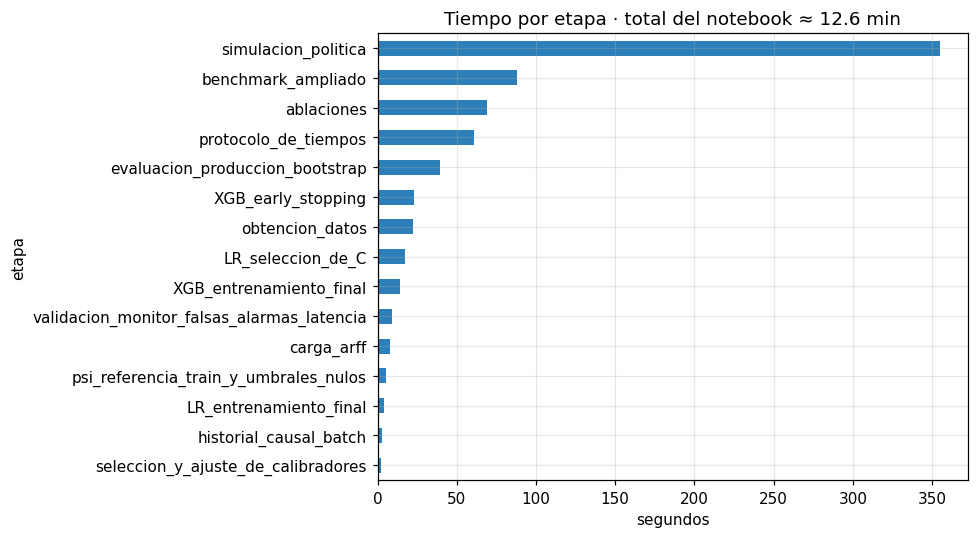

Tiempo total de ejecución: 753.8 s en 2 CPU lógicos. RNF-03 (≤ 90 min para los tres datasets ≈ 30 min por dataset): ✅ cumple
Paquete de artefactos: /content/artifacts/airline/tt2_airline_20261018T143237Z.zip


,segundos
etapa,
simulacion_politica,354.948
benchmark_ampliado,88.112
ablaciones,69.155
protocolo_de_tiempos,60.925
evaluacion_produccion_bootstrap,39.348
XGB_early_stopping,22.856
obtencion_datos,22.491
LR_seleccion_de_C,17.188
XGB_entrenamiento_final,14.186


In [36]:
timings_df = pd.DataFrame(TIMINGS)
save_table(timings_df, "tiempos_etapas")
total = time.perf_counter() - NOTEBOOK_T0
agg = timings_df.groupby("etapa", sort=False)["segundos"].sum().sort_values(ascending=False)
ax = agg.head(15).iloc[::-1].plot(kind="barh", figsize=(9, 5), color="#2c7fb8",
                                    title=f"Tiempo por etapa · total del notebook ≈ {total / 60:.1f} min")
ax.set_xlabel("segundos")
plt.tight_layout()
plt.show()
print(f"Tiempo total de ejecución: {total:,.1f} s en {ENV['cpus_logicos']} CPU lógicos. "
      f"RNF-03 (≤ 90 min para los tres datasets ≈ 30 min por dataset): {'✅ cumple' if total < 30 * 60 else '⚠️ revisar'}")
zip_path = shutil.make_archive(str(ART), "zip", ART)
print(f"Paquete de artefactos: {zip_path}")
if IN_COLAB and CONFIG["download_artifacts"]:
    from google.colab import files
    files.download(zip_path)
agg.round(3).to_frame("segundos")

### Cierre: observaciones del jurado resueltas en este notebook
| # | Observación | Evidencia en el notebook |
|---|---|---|
| 1 | Tiempos de procesamiento | `%%time` en entrenamientos; `TIMINGS` por etapa con memoria; protocolo con repeticiones y hardware, incluido el costo del historial (§3.5); costo en segundos de cada intervención (§4.6); resumen (§5.5). |
| 2 | Justificación de modelos | Argumentación técnica (§3.1); ablaciones de codificación, historial, pesos y dimensionalidad (§3.6); benchmark de 5 candidatos con desempeño, calibración y tiempo (§3.7). |
| 3 | Explicación sin tecnicismos | Ficha en lenguaje llano (§1.5) y explicación del historial (§2.3), reutilizables en la vista P2. |
| 4 | Requisitos de dataset candidato | `validate_dataset()`: detecta el orden intradía y el identificador `Flight` que invalidaban el esquema de TT1 (§1.7). |
| 5 | Maquetado del dashboard | Contrato de artefactos por vista, `predict_delay()` y actualización del historial probados (§5.1–5.4). |
| 6 | Estático vs ajuste de dimensionalidad | Esquema congelado por versión; en Airline se *expande* con historial y se controla la dimensión del one-hot (§2.5, §3.6). |